# Duplicate-aware oral image classification on CPU
## A controlled study of HOG–Lab fusion and camera degradation

**Task.** Predict the uploader's image-level category on [Oral_Image_Dataset, version 1](https://www.kaggle.com/datasets/jhirshaikh/oral-image-dataset). Kaggle's listing API reports 450,189,730 bytes and CC0. The uploader [describes curating public Kaggle sources](https://in.linkedin.com/in/zahir-shaikh-54159537a). The audit below measures archive contents and class balance directly. The retrieved archive SHA-256 was `dc4e86980b7d6f988e695236ca63195a406dfa7b422865f77b355d14a926fa2f`. Category folders provide weak supervision. Patient identity, source-clinic membership, diagnosis verification and co-occurring conditions require independent provenance. The intended application is research on inexpensive photo categorization and image quality, with clinical usefulness requiring separate evidence.

### Archive audit from the reference run

| Uploader label | Image files | Exact-unique, conflict-free |
|---|---:|---:|
| Calculus | 1,296 | 801 |
| Caries | 219 | 194 |
| Hypodontia | 1,251 | 1,224 |
| Mouth ulcer | 265 | 243 |
| Normal | 286 | 284 |
| Tooth discoloration | 1,058 | 1,048 |
| Total | 4,375 | 3,794 |

All candidate files decoded. The exclusions comprise 460 exact copies and 121 images in 27 conflicting decoded-pixel groups. The retained dimensions range from 121 to 4,160 pixels wide and 33 to 4,624 pixels tall. The perceptual audit produced 2,660 groups, including 278 multi-image groups. Among retained images, the Normal folder had a median width of 1,898 pixels, compared with 276 for Tooth discoloration. Different image sizes suggest acquisition or curation differences correlated with labels. In an illustrative random stratified 80/20 split of the same exact-deduplicated images, 275 of 759 held-out images had a perceptual group represented on the training side. This quantifies overlap under the chosen hash heuristic. The grouped 2,276/759/759 protocol keeps each estimated group in one partition.

### Research directions considered

| Direction | Research value and gap | Fit, compute and publication potential |
|---|---|---|
| Duplicate-aware texture–color fusion and camera stress tests | Tests whether spatial chroma complements gradients and survives photographic degradation. Duplicate auditing addresses an identifiable reproducibility risk. | Uses folder labels and image pixels. Low additional compute. Strongest fit for a reproducible benchmark or applied methods paper if effects and provenance hold up. |
| Frozen CNN compression and efficiency | Tests embedding widths and CPU cost, but classifier compression alone says little about backbone cost. | Feasible, with limited methodological differentiation unless validated on real target hardware and additional data. |
| Source generalization and selective prediction | Source-held-out evaluation could reveal shortcut learning and support abstention research. | High significance, but reliable source or patient identifiers and an independent cohort are prerequisites. Synthetic corruptions address only a subset of the generalization problem. |

### Related work and bounded research gap

- [Fu et al., EClinicalMedicine (2020)](https://doi.org/10.1016/j.eclinm.2020.100558) developed oral cancer recognition from clinical photographs, with biopsy-confirmed cases and image quality screening. That endpoint differs from uploader-defined multiclass image categories.
- [Zhang et al., Oral Diseases (2022)](https://doi.org/10.1111/odi.13735) investigated deep learning for caries screening on photos. [Park et al., BMC Oral Health (2022)](https://doi.org/10.1186/s12903-022-02589-1) tested tooth-surface segmentation in prospective intraoral images. The current benchmark uses image-level labels.
- [Rokhshad et al., Clinical Oral Investigations (2024)](https://doi.org/10.1007/s00784-023-05475-4) reviewed photographic oral mucosa lesion detection and classification. [The 2025 clinical photography review](https://pmc.ncbi.nlm.nih.gov/articles/PMC11931071/) discusses image quality, imbalance and validation issues.
- [A 2026 BMC Oral Health hybrid study](https://doi.org/10.1186/s12903-026-08552-8) evaluated hybrid deep models on a curated dental-condition collection. [MultiDentNet (2026)](https://doi.org/10.1038/s41598-026-52264-6) studied multiclass dental images and lesion triage. The hybrid study reused fine-tuned CNN features with classical classifier heads, while MultiDentNet combined multiclass dental classification with a separate lesion task. Both cite the Salman Sajid oral-diseases archive. Treat them as related benchmarks. Overlap with upstream sources remains possible.
- [Tampu et al., Scientific Data (2022)](https://doi.org/10.1038/s41597-022-01618-6) quantified split leakage in OCT. Its effect sizes are specific to those OCT experiments. [HOG](https://doi.org/10.1109/CVPR.2005.177), [LeNet](https://doi.org/10.1109/5.726791), [EfficientNet](https://proceedings.mlr.press/v97/tan19a.html) and [MobileNetV2](https://openaccess.thecvf.com/content_cvpr_2018/html/Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.html) motivate the reference implementations.

**Gap addressed.** The reviewed studies leave open whether cheap spatial chroma adds useful information to gradient features on this particular release under an audited split, and what it costs in inference time. The contribution is the controlled evaluation and an inexpensive recipe, with no priority claim for HOG, Lab, or their concatenation.

### Research objectives, questions and hypotheses

1. Audit class labels, image quality and duplicate clusters. How much repeated content can the audit identify, and what split survives grouping?
2. Evaluate all seven models with common held-out data. Which architecture wins on clean macro-F1, and which lie on the latency–macro-F1 frontier?
3. Test the proposed method. **Primary hypothesis:** block-normalized HOG–Lab fusion with one deterministic camera-perturbed training copy per image improves clean test macro-F1 over the validation-selected mandatory baseline. The observed effect may be negative.
4. **Secondary hypotheses:** Lab adds information beyond HOG when learner, regularization and preprocessing are held constant. Camera augmentation reduces degradation relative to clean-only fusion. Aspect-preserving resize versus stretch is exploratory.

**Design.** One frozen split, validation-only model selection, all test images retained after audit, paired group-level inference. HOG grayscale captures local gradients. Spatial Lab histograms preserve regional chroma. Standardize each feature using training moments and scale each block by its square-root width before concatenation. Use a balanced Linear SVM. A clean-only fusion, HOG-only and Lab-only ablations, and a stretch-resize control isolate the main design choices.

### Experimental roadmap

| Experiment | Comparison and purpose |
|---|---|
| 1. Baselines | Seven required models on the common grouped split |
| 2. Preprocessing | Aspect preservation versus stretch with the same fusion classifier |
| 3. Representation | HOG, Lab, and fusion under the same learner and augmented views |
| 4. Tuning | Two ANN configurations, two RF depths, three SVM C values, and validation-selected CNN checkpoints |
| 5. Proposed method | Augmented fusion versus the mandatory models, with a primary validation-selected comparator |
| 6. Ablations | Remove either feature block or camera augmentation |
| 7. Errors | Classwise metrics, top confusion directions, and representative images |
| 8. Robustness | Fixed blur, dimming and JPEG on the same held-out images |
| 9. Statistical analysis | Group bootstrap and a primary paired prediction-swap test |

## 1 · Kaggle CPU setup
Create a Kaggle Notebook, attach the exact dataset, select **Accelerator → None**, and run all cells. Internet or locally attached Keras weight files enable ImageNet initialization. For an offline reference run, attach the official [EfficientNetB0 weights](https://storage.googleapis.com/keras-applications/efficientnetb0_notop.h5) and [MobileNetV2 96×96 weights](https://storage.googleapis.com/tensorflow/keras-applications/mobilenet_v2/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_96_no_top.h5), then set the two `LOCAL_WEIGHTS` paths in the setup cell. If weights cannot be fetched, the two backbone models train from scratch and their actual initialization is recorded. Avoid comparing a scratch run to claims about transfer learning. Configure a class root or a folder mapping only if the printed manifest shows an unexpected archive layout. Outputs go to `oral_results` under the working directory.

In [ ]:
from pathlib import Path
import os, sys, io, json, time, hashlib, random, warnings, inspect, shutil
from collections import defaultdict
from importlib.metadata import version

SEED = 42
THREADS = min(4, os.cpu_count() or 1)
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS',
            'TF_NUM_INTRAOP_THREADS', 'TF_NUM_INTEROP_THREADS'):
    os.environ[key] = str(THREADS)
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from PIL import Image, ImageOps, ImageFilter, ImageEnhance
    from scipy.fft import dctn
    from scipy.ndimage import laplace
    from skimage.feature import hog
    from skimage.color import rgb2lab
    import sklearn
    from sklearn.model_selection import StratifiedGroupKFold
    from sklearn.neural_network import MLPClassifier
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.svm import LinearSVC
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    from sklearn.utils.class_weight import compute_sample_weight
    from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
        classification_report, confusion_matrix, roc_auc_score, average_precision_score, roc_curve)
    from threadpoolctl import threadpool_limits
    import joblib
    import tensorflow as tf
    from tensorflow import keras
    from IPython.display import display
except ImportError as exc:
    raise RuntimeError('Use a Kaggle Python CPU image with TensorFlow, scikit-image, Pillow and scikit-learn.') from exc

threadpool_limits(THREADS)
random.seed(SEED)
np.random.seed(SEED)
tf.config.set_visible_devices([], 'GPU')
tf.config.threading.set_intra_op_parallelism_threads(THREADS)
tf.config.threading.set_inter_op_parallelism_threads(2)
keras.utils.set_random_seed(SEED)

ROOT = Path(os.getenv('ORAL_DATA_ROOT', '/kaggle/input/jhirshaikh/oral-image-dataset'))
if not ROOT.exists() and 'ORAL_DATA_ROOT' not in os.environ:
    alternatives = [Path('/kaggle/input/oral-image-dataset'),
                    Path('/kaggle/input/datasets/jhirshaikh/oral-image-dataset')]
    ROOT = next((path for path in alternatives if path.is_dir()), ROOT)
CLASS_FOLDERS = {}  # Optional {'archive/relative/class_folder': 'class label'}
default_out = Path('/kaggle/working/oral_results') if Path('/kaggle/working').is_dir() else Path('oral_results')
OUT = Path(os.getenv('ORAL_RESULTS', str(default_out))).resolve()
OUT.mkdir(parents=True, exist_ok=True)
MODELS = OUT / 'models'
MODELS.mkdir(exist_ok=True)
SIZE = 96
BATCH = 32
TRAIN_LIMIT = 7000
EPOCHS = int(os.getenv('ORAL_EPOCHS', '12'))
SCRATCH_EPOCHS = min(EPOCHS, 5)
TRY_IMAGENET = os.getenv('ORAL_IMAGENET', '1') == '1'
LOCAL_WEIGHTS = {'EfficientNetB0': os.getenv('ORAL_EFFICIENTNET_WEIGHTS'),
                 'MobileNetV2': os.getenv('ORAL_MOBILE_WEIGHTS')}
env = {'root': str(ROOT), 'seed': SEED, 'threads': THREADS, 'size': SIZE,
       'python': sys.version, 'tensorflow': tf.__version__, 'sklearn': sklearn.__version__,
       'pillow': version('Pillow'), 'skimage': version('scikit-image'),
       'epochs': EPOCHS, 'training_limit': TRAIN_LIMIT, 'try_imagenet': TRY_IMAGENET}
(OUT/'environment.json').write_text(json.dumps(env, indent=2))
print(env)

## 2 · Dataset loading and data quality audit
Inspect file types, original image geometry, decoded pixels and a blur proxy. EXIF orientation is normalized before hashing. Exact decoded RGB copies collapse to one representative. Exact copies with conflicting labels are excluded. Approximate grouping uses 64-bit DCT pHash with Hamming distance ≤6, including mirrored variants. Seven disjoint hash bands give a candidate match for every pair within six bit flips. Connected components stay together across splits, including mixed-label components. Similarity is a proxy and may merge unrelated images or miss crops, rotations, and other photos of the same patient.

In [ ]:
if not ROOT.is_dir():
    raise FileNotFoundError(f'Attach jhirshaikh/oral-image-dataset or set ORAL_DATA_ROOT. Looked in {ROOT}')
extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tiff', '.tif', '.jfif', '.gif'}
files = sorted(p for p in ROOT.rglob('*') if p.is_file())
images = [p for p in files if p.suffix.lower() in extensions and '__MACOSX' not in p.parts]
if not images:
    raise ValueError(f'No supported images under {ROOT}')
split_names = {'train', 'training', 'val', 'valid', 'validation', 'test', 'testing'}
excluded_parent = split_names | {'images', 'image', 'oral image dataset', 'oral_image_dataset',
                                 'augmented', 'original', 'dataset', 'data'}

def get_label(path):
    parent = path.relative_to(ROOT).parent
    if CLASS_FOLDERS:
        return next((CLASS_FOLDERS[x.as_posix()] for x in [parent, *parent.parents]
                     if x.as_posix() in CLASS_FOLDERS), None)
    return next((x.strip().lower() for x in reversed(parent.parts)
                 if x.strip().lower() not in excluded_parent), None)

def read_rgb(path):
    with Image.open(path) as img:
        return ImageOps.exif_transpose(img).convert('RGB')

def phash(gray):
    coeff = dctn(gray, norm='ortho')[:8, :8].ravel()
    bits = coeff > np.median(coeff[1:])
    bits[0] = False
    return int.from_bytes(np.packbits(bits).tobytes(), 'big')

def audit_image(path):
    rgb = read_rgb(path)
    small = np.asarray(rgb.convert('L').resize((32, 32), Image.Resampling.LANCZOS), dtype=float)
    digest = hashlib.sha256(f'{rgb.width}x{rgb.height}:'.encode() + rgb.tobytes()).hexdigest()
    return rgb.width, rgb.height, float(laplace(small).var()), digest, phash(small), phash(small[:, ::-1])

rows, unreadable = [], []
for path in images:
    rel = path.relative_to(ROOT).as_posix()
    label = get_label(path)
    if label is None:
        raise ValueError(f'Cannot infer label for {rel}. Configure CLASS_FOLDERS.')
    try:
        rows.append((rel, label, *audit_image(path)))
    except (OSError, ValueError, Image.DecompressionBombError) as exc:
        unreadable.append((rel, label, str(exc)))
columns = ['path','label','width','height','blur_proxy','sha256','phash','mirror_hash']
raw = pd.DataFrame(rows, columns=columns)
if raw.empty:
    raise ValueError('No decodable labeled images')
bad = pd.DataFrame(unreadable, columns=['path','label','error'])
bad.to_csv(OUT/'unreadable.csv', index=False)
pd.DataFrame({'path': [p.relative_to(ROOT).as_posix() for p in files if p not in set(images)]}
             ).to_csv(OUT/'other_files.csv', index=False)
counts_by_hash = raw.groupby('sha256')['label'].transform('nunique')
raw['status'] = np.where(counts_by_hash > 1, 'exact_label_conflict',
                np.where(raw.duplicated('sha256'), 'exact_copy', 'retained'))
raw.to_csv(OUT/'image_audit.csv', index=False)
data = raw[raw.status == 'retained'].copy().reset_index(drop=True)
if set(data.label) != set(raw.label):
    raise ValueError('Audit removed a complete class. Inspect image_audit.csv.')
classes = sorted(data.label.unique())
if not 2 <= len(classes) <= 40:
    raise ValueError(f'Unexpected class folders: {classes}. Configure CLASS_FOLDERS.')
K = len(classes)
LABELS = np.arange(K)
y = pd.Categorical(data.label, categories=classes).codes.astype(int)
print('Image candidates:', len(images), 'Unreadable:', len(bad))
display(pd.crosstab(raw.label, raw.status))
display(raw[['width','height','blur_proxy']].describe().round(2))
print('Example paths per inferred class:')
display(raw.groupby('label').path.first())
display(data.groupby('label')[['width','height','blur_proxy']].median().round(1))

In [ ]:
parents = list(range(len(data)))

def leader(i):
    while i != parents[i]:
        parents[i] = parents[parents[i]]
        i = parents[i]
    return i

def join(i, j):
    a, b = leader(i), leader(j)
    parents[max(a,b)] = min(a,b)

bands = [(9*i, 9) for i in range(6)] + [(54, 10)]
buckets = defaultdict(list)
edges = []
for i, (h, mirror) in enumerate(data[['phash','mirror_hash']].itertuples(index=False, name=None)):
    for key_hash in {int(h), int(mirror)}:
        keys = [(b, (key_hash >> shift) & ((1 << width)-1))
                for b, (shift, width) in enumerate(bands)]
        candidates = set(j for key in keys for j in buckets[key])
        for j in candidates:
            distance = min((key_hash ^ int(data.at[j,c])).bit_count()
                           for c in ('phash','mirror_hash'))
            if j != i and distance <= 6 and leader(i) != leader(j):
                edges.append((j, i, distance))
                join(i, j)
        for key in keys:
            buckets[key].append(i)
groups = np.array([leader(i) for i in range(len(data))])
data['group'] = groups
pair_columns = ['left_row','right_row','hamming']
pd.DataFrame(edges, columns=pair_columns).to_csv(OUT/'duplicate_link_tree.csv', index=False)
summary = data.groupby('group').agg(images=('path','size'), labels=('label','nunique'))
summary.to_csv(OUT/'duplicate_groups.csv')
print(f'{len(data)} exact-unique images, {len(summary)} groups, '
      f'{(summary.images > 1).sum()} multi-image groups, '
      f'{(summary.labels > 1).sum()} mixed-label groups, largest group {summary.images.max()}')
display(data.groupby('label').agg(images=('path','size'), groups=('group','nunique')))

## 3 · Split, class distribution, and preprocessing
Regroup across any uploader-provided train/test folders because shared source images can cross those boundaries. A stratified group split targets approximately 60/20/20. Among candidate folds, choose by class counts and sizes only. A deterministic train-only cap of 7,000 images, allocated by class, applies only for large archives. Record all exclusions and indices. Every model sees the same training originals and final test set. Weight classes by inverse training frequency. Resize to 96×96 preserving aspect ratio via edge padding. Stretch is an experimental control. Retain uint8 buffers and convert to float in the models. A blur proxy flags low detail for descriptive inspection. It does not gate exclusion.

In [ ]:
if data.groupby('label').group.nunique().min() < 3:
    raise ValueError('At least three distinct groups per class are needed for this design.')

def holdout(ids, folds, seed):
    candidates = []
    target = np.bincount(y[ids], minlength=K) / folds
    splitter = StratifiedGroupKFold(folds, shuffle=True, random_state=seed)
    for fit, hold in splitter.split(ids, y[ids], groups[ids]):
        actual = np.bincount(y[ids[hold]], minlength=K)
        if len(np.unique(y[ids[fit]])) == K and (actual > 0).all():
            error = np.mean(np.abs(actual-target) / np.maximum(target, 1))
            candidates.append((error, ids[fit], ids[hold]))
    return candidates

all_ids = np.arange(len(data))
partitions = []
for offset in range(8):
    for e1, remaining, test in holdout(all_ids, 5, SEED+offset):
        for e2, train, val in holdout(remaining, 4, SEED+offset):
            partitions.append((e1+e2, train, val, test))
if not partitions:
    raise ValueError('Could not build three class-complete, group-disjoint partitions.')
_, train, val, test = min(partitions, key=lambda p: p[0])
data['split'] = 'train_excluded_by_cap'
data.loc[val, 'split'] = 'validation'
data.loc[test, 'split'] = 'test'
if len(train) > TRAIN_LIMIT:
    from sklearn.model_selection import train_test_split
    train, _ = train_test_split(train, train_size=TRAIN_LIMIT, stratify=y[train], random_state=SEED)
train, val, test = map(np.sort, (train,val,test))
for a,b in [(train,val),(train,test),(val,test)]:
    assert not set(groups[a]).intersection(groups[b])
assert all(len(np.unique(y[ids])) == K for ids in (train,val,test))
data.loc[train,'split'] = 'train'
data.to_csv(OUT/'split_manifest.csv', index_label='row')
part_counts = pd.crosstab(data.label,data.split)
part_counts.to_csv(OUT/'split_counts.csv')
display(part_counts)
ax = part_counts.plot.bar(figsize=(10,4), ylabel='Images', xlabel='')
ax.figure.tight_layout()
ax.figure.savefig(OUT/'split_distribution.pdf')
plt.show()

def resize_image(img, stretch=False):
    if stretch:
        return np.asarray(img.resize((SIZE,SIZE), Image.Resampling.BILINEAR))
    fitted = ImageOps.contain(img, (SIZE,SIZE), Image.Resampling.BILINEAR)
    array = np.asarray(fitted)
    h,w = array.shape[:2]
    dh,dw = SIZE-h,SIZE-w
    return np.pad(array, ((dh//2,dh-dh//2),(dw//2,dw-dw//2),(0,0)), mode='edge')

started = time.perf_counter()
X = np.zeros((len(data),SIZE,SIZE,3), np.uint8)
for i in np.sort(np.r_[train,val,test]):
    X[i] = resize_image(read_rgb(ROOT/data.at[i,'path']))
preprocessing_seconds = time.perf_counter()-started
print(f'Resized cache {X.nbytes/2**20:.1f} MiB in {preprocessing_seconds:.1f} s')

## 4 · HOG, Lab and camera augmentation
Use the same 9-bin, 12-pixel-cell, 2×2-block L2-Hys HOG for all traditional baselines. Spatial Lab uses eight bins per channel in each quadrant. Lab separates lightness from chroma, while histogram pooling makes small displacements less consequential. The main fusion trains on one extra view per training original, cycling through moderate blur, underexposure and JPEG compression. CNNs trained end to end use horizontal flip and mild rotation. Frozen backbones cache features for clean and horizontally flipped training views. Validation and clean test data always use their original views.

In [ ]:
def hog_vector(image):
    gray = np.asarray(Image.fromarray(image).convert('L'), dtype=np.float32) / 255
    return hog(gray, orientations=9, pixels_per_cell=(12,12), cells_per_block=(2,2),
               block_norm='L2-Hys').astype(np.float32)

def lab_vector(image):
    lab = rgb2lab(image)
    half = SIZE//2
    bins = [(0,100),(-128,128),(-128,128)]
    values = []
    for r,c in [(0,0),(0,half),(half,0),(half,half)]:
        tile = lab[r:r+half,c:c+half]
        for j,(lo,hi) in enumerate(bins):
            hist,_ = np.histogram(np.clip(tile[:,:,j],lo,hi), bins=8, range=(lo,hi))
            values.extend(hist / (half**2))
    return np.asarray(values,dtype=np.float32)

def extract(batch, kind):
    if kind == 'hog':
        return np.stack([hog_vector(im) for im in batch])
    if kind == 'lab':
        return np.stack([lab_vector(im) for im in batch])
    return np.stack([np.r_[hog_vector(im),lab_vector(im)] for im in batch])

def perturb(image, condition):
    pil = Image.fromarray(image)
    if condition == 'Blur':
        return np.asarray(pil.filter(ImageFilter.GaussianBlur(1.15)))
    if condition == 'Dim':
        return np.asarray(ImageEnhance.Brightness(pil).enhance(0.68))
    if condition == 'JPEG':
        buffer = io.BytesIO()
        pil.save(buffer, format='JPEG', quality=30)
        buffer.seek(0)
        with Image.open(buffer) as decoded:
            return np.array(decoded.convert('RGB'))
    raise ValueError(condition)

conditions = ('Blur','Dim','JPEG')
def measure(operation):
    t = time.perf_counter()
    result = operation()
    return result,time.perf_counter()-t

H, hog_seconds = measure(lambda: extract(X,'hog'))
L, lab_seconds = measure(lambda: extract(X,'lab'))
np.savez_compressed(OUT/'clean_features.npz', hog=H, lab=L)
weights = compute_sample_weight('balanced',y[train]).astype(np.float32)
print('HOG and Lab dimensions:', H.shape[1], L.shape[1])

## 5 · Traditional classifiers and limited hyperparameter optimization
Select settings by validation macro-F1. ANN uses one ReLU hidden layer with early model selection by choosing between two capacity/regularization settings and a bounded iteration budget. Random Forest tunes tree depth with 120 trees. Linear SVM tunes C. Scaling is fitted inside each training pipeline. The forest uses HOG directly. Older scikit-learn releases without weighted MLP fitting use deterministic training-only oversampling for the ANN. Uncalibrated SVM margins support ranking AUC metrics.

In [ ]:
mandatory = ['ANN (HOG)','Random Forest (HOG)','Linear SVM (HOG)','LeNet-style CNN',
             'Custom CNN','EfficientNetB0','MobileNetV2']
proposed = 'HOG–Lab fusion + camera augmentation'
registry = {}
tuning = []
def macro(truth,pred):
    return f1_score(truth,pred,labels=LABELS,average='macro',zero_division=0)

def scores_for(model, features):
    if hasattr(model,'decision_function'):
        score = model.decision_function(features)
        return np.c_[-score,score] if score.ndim == 1 else score
    return model.predict_proba(features)

def register_ml(name, model, kind, val_features, seconds, prep, config):
    core = model[-1] if hasattr(model,'steps') else model
    parameters = None
    nodes = None
    if hasattr(core,'coefs_'):
        parameters = sum(a.size for a in [*core.coefs_,*core.intercepts_])
    if hasattr(core,'coef_'):
        parameters = core.coef_.size + core.intercept_.size
    if hasattr(core,'estimators_'):
        nodes = sum(tree.tree_.node_count for tree in core.estimators_)
    path = MODELS/f'{len(registry):02d}.joblib'
    joblib.dump({'model':model,'classes':classes,'feature':kind,'size':SIZE},path,compress=3)
    registry[name] = dict(model=model, feature=kind, fit_s=seconds, prep_s=prep,
        init='trained on archive', trainable=parameters, parameters=parameters, tree_nodes=nodes,
        size_mib=path.stat().st_size/2**20, path=str(path), config=config,
        validation_macro_f1=macro(y[val],model.predict(val_features)))

def tune_hog(name, candidates):
    fitted = []
    for model, settings in candidates:
        fit_ids = train
        kwargs = {'sample_weight':weights}
        if hasattr(model,'steps'):
            kwargs = {f'{model.steps[-1][0]}__sample_weight':weights}
        if name == mandatory[0] and 'sample_weight' not in inspect.signature(model[-1].fit).parameters:
            # Older sklearn releases lack weighted MLP fitting. Keep all originals and oversample.
            rng = np.random.default_rng(SEED)
            by_class = [train[y[train] == i] for i in LABELS]
            target = max(map(len, by_class))
            extra = [rng.choice(ids, size=target-len(ids), replace=True) for ids in by_class]
            fit_ids = np.concatenate([train, *extra])
            kwargs = {}
            settings = {**settings, 'imbalance_fallback':'train-only oversampling'}
        _, seconds = measure(lambda: model.fit(H[fit_ids],y[fit_ids],**kwargs))
        f1 = macro(y[val],model.predict(H[val]))
        tuning.append(dict(model=name,settings=str(settings),val_macro_f1=f1,fit_s=seconds))
        fitted.append((f1,model,seconds,settings))
    _, model,seconds,settings = max(fitted,key=lambda row:row[0])
    register_ml(name,model,'hog',H[val],seconds,hog_seconds,settings)

tune_hog(mandatory[0], [
    (make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(width,), alpha=alpha,
      max_iter=35, batch_size=64, random_state=SEED, n_iter_no_change=5)), {'width':width,'alpha':alpha})
    for width,alpha in [(48,0.001),(96,0.01)]])
tune_hog(mandatory[1], [
    (RandomForestClassifier(n_estimators=120,max_depth=depth,min_samples_leaf=2,
      n_jobs=THREADS,random_state=SEED), {'depth':depth}) for depth in (16,None)])
tune_hog(mandatory[2], [
    (make_pipeline(StandardScaler(),LinearSVC(C=c,dual='auto',max_iter=4000,random_state=SEED)),
      {'C':c}) for c in (0.001,0.01,0.1)])
display(pd.DataFrame(tuning).round(4))

## 6 · LeNet-style CNN and custom CNN
LeNet uses two tanh convolution stages, average pooling and dense classification on grayscale intensity. The custom CNN uses a strided RGB stem, separable convolutions, batch normalization, global average pooling and dropout. These choices bound CPU cost and remove a large flatten-and-dense stage. All neural models use inverse-frequency sample weights. Select each checkpoint by validation macro-F1 with early stopping and a maximum of 12 epochs.

In [ ]:
layers = keras.layers
keras_options = tf.data.Options()
keras_options.threading.private_threadpool_size = 2
keras_options.threading.max_intra_op_parallelism = THREADS

def batches(xs, ys, w=None, shuffle=False):
    if w is None:
        ds = tf.data.Dataset.from_tensor_slices((xs,ys))
    else:
        ds = tf.data.Dataset.from_tensor_slices((xs,ys,w))
    if shuffle:
        ds = ds.shuffle(len(xs),seed=SEED,reshuffle_each_iteration=True)
    return ds.batch(BATCH).with_options(keras_options).prefetch(1)

def forward(model, xs):
    return np.concatenate([np.asarray(model(xs[i:i+BATCH],training=False))
                           for i in range(0,len(xs),BATCH)])

class ValidationMacroF1(keras.callbacks.Callback):
    def __init__(self, features):
        super().__init__()
        self.features = features
    def on_epoch_end(self, epoch, logs=None):
        logs['val_macro_f1'] = macro(y[val],forward(self.model,self.features).argmax(1))

def fit_neural(model, xs, ys, w, validation, epochs, name):
    model.compile(optimizer=keras.optimizers.Adam(0.001), loss='sparse_categorical_crossentropy')
    stop = keras.callbacks.EarlyStopping(monitor='val_macro_f1',mode='max',patience=3,
                                          restore_best_weights=True)
    history, sec = measure(lambda: model.fit(batches(xs,ys,w,True),
                validation_data=batches(validation,y[val]),
                epochs=epochs, callbacks=[ValidationMacroF1(validation),stop],verbose=2))
    pd.DataFrame(history.history).to_csv(OUT/f'history_{mandatory.index(name)}.csv', index=False)
    return sec, len(history.epoch)

def augmenter():
    return keras.Sequential([layers.RandomFlip('horizontal',seed=SEED),
                             layers.RandomRotation(0.035,seed=SEED+1)],name='train_augmentation')

def register_neural(name, model, seconds, prep, init, epochs):
    path = MODELS/f'{len(registry):02d}.keras'
    model.save(path,include_optimizer=False)
    registry[name] = dict(model=model,feature='rgb',fit_s=seconds,prep_s=prep,init=init,
        trainable=int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        parameters=model.count_params(),tree_nodes=None,size_mib=path.stat().st_size/2**20,
        path=str(path),config={'epochs_run':epochs},validation_macro_f1=macro(y[val],forward(model,X[val]).argmax(1)))

keras.utils.set_random_seed(SEED)
inputs = keras.Input((SIZE,SIZE,3))
z = augmenter()(inputs)
z = layers.Rescaling(1/255)(z)
z = layers.Conv2D(1,1,use_bias=False,trainable=False,kernel_initializer=
                  keras.initializers.Constant(np.array([0.299,0.587,0.114]).reshape(1,1,3,1)))(z)
z = layers.AveragePooling2D(2)(z)
for width in (6,16):
    z = layers.Conv2D(width,5,activation='tanh')(z)
    z = layers.AveragePooling2D(2)(z)
z = layers.Flatten()(z)
z = layers.Dense(120,activation='tanh')(z)
z = layers.Dense(84,activation='tanh')(z)
lenet = keras.Model(inputs,layers.Dense(K,activation='softmax')(z),name='lenet_style')
sec,epochs = fit_neural(lenet,X[train],y[train],weights,X[val],EPOCHS,mandatory[3])
register_neural(mandatory[3],lenet,sec,0,'random initialization',epochs)

In [ ]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input((SIZE,SIZE,3))
z = layers.Rescaling(1/255)(augmenter()(inputs))
z = layers.Conv2D(24,3,strides=2,padding='same',use_bias=False)(z)
z = layers.Activation('relu')(layers.BatchNormalization()(z))
for width in (32,64,96):
    z = layers.SeparableConv2D(width,3,strides=2,padding='same',use_bias=False)(z)
    z = layers.Activation('relu')(layers.BatchNormalization()(z))
z = layers.GlobalAveragePooling2D()(z)
z = layers.Dropout(0.25)(z)
custom = keras.Model(inputs,layers.Dense(K,activation='softmax')(z),name='custom_cnn')
sec,epochs = fit_neural(custom,X[train],y[train],weights,X[val],EPOCHS,mandatory[4])
register_neural(mandatory[4],custom,sec,0,'random initialization',epochs)

## 7 · EfficientNetB0 and MobileNetV2
Use full-width Keras application backbones at 96×96 and identical softmax heads. EfficientNet receives 0–255 RGB with built-in scaling. MobileNetV2 receives RGB scaled to [−1,1]. Prefer ImageNet weights, freeze the backbone, and cache training plus validation embeddings. A pretrained run fits only the classification head. An unavailable-weights run trains the full architecture for up to five epochs and reports random initialization. The benchmark times inference through the full backbone.

In [ ]:
def fit_backbone(name, constructor):
    keras.utils.set_random_seed(SEED)
    kwargs = dict(include_top=False,input_shape=(SIZE,SIZE,3),pooling='avg')
    local_path = LOCAL_WEIGHTS[name]
    if local_path:
        filenames = {'EfficientNetB0':'efficientnetb0_notop.h5',
                     'MobileNetV2':'mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_96_no_top.h5'}
        cache = Path(os.getenv('KERAS_HOME', str(Path.home()/'.keras'))) / 'models'
        cache.mkdir(parents=True,exist_ok=True)
        source = Path(local_path)
        target = cache / filenames[name]
        if source.resolve() != target.resolve():
            shutil.copyfile(source,target)
        backbone = constructor(weights='imagenet',**kwargs)
        init = 'ImageNet (locally supplied Keras weights)'
        frozen = True
    elif TRY_IMAGENET:
        try:
            backbone = constructor(weights='imagenet',**kwargs)
            init, frozen = 'ImageNet (Keras)', True
        except Exception as exc:
            warnings.warn(f'{name} ImageNet load failed ({type(exc).__name__}). Training from scratch.')
            backbone = constructor(weights=None,**kwargs)
            init, frozen = 'random initialization (ImageNet unavailable)', False
    else:
        backbone = constructor(weights=None,**kwargs)
        init, frozen = 'random initialization (ImageNet disabled)', False

    backbone.trainable = not frozen
    inputs = keras.Input((SIZE,SIZE,3))
    z = inputs if frozen else augmenter()(inputs)
    if name == 'MobileNetV2':
        z = layers.Rescaling(1/127.5,offset=-1)(z)
    z = backbone(z,training=False) if frozen else backbone(z)
    head = keras.Sequential([keras.Input((backbone.output_shape[-1],)),
                            layers.Dropout(0.25),layers.Dense(K,activation='softmax')])
    full = keras.Model(inputs,head(z),name=name.lower())
    if frozen:
        encoder = keras.Model(inputs,z)
        def embeddings():
            return (np.concatenate([forward(encoder,X[train]),forward(encoder,X[train][:,:,::-1,:].copy())]),
                    forward(encoder,X[val]))
        (f_train,f_val), prep = measure(embeddings)
        sec,epochs = fit_neural(head,f_train,np.tile(y[train],2),np.tile(weights,2),f_val,EPOCHS,name)
    else:
        prep = 0
        sec,epochs = fit_neural(full,X[train],y[train],weights,X[val],SCRATCH_EPOCHS,name)
    register_neural(name,full,sec,prep,init,epochs)
    print(name, init, f'fit={sec:.1f}s; embedding preparation={prep:.1f}s')

In [ ]:
fit_backbone('EfficientNetB0',keras.applications.EfficientNetB0)

In [ ]:
fit_backbone('MobileNetV2',keras.applications.MobileNetV2)

## 8 · Proposed method, preprocessing control and ablations
The balanced linear SVM receives standardized feature blocks divided by the square root of their width. This keeps the 1,764 HOG coordinates from dominating simply through dimensionality. For a block with width $d_b$, each coordinate is transformed to $(x_j-\mu_j)/(\sigma_j\sqrt{d_b})$ with training-only statistics and unit scale for constant features. Predeclare C=10 across all ablations. Train the clean and camera-augmented fusion variants with identical feature and optimizer settings. HOG-only and Lab-only use the same augmented examples and block scaling. Use the stretch condition only to isolate resizing. The HOG-only ablation differs from the mandatory tuned SVM in augmentation and regularization.

In [ ]:
HOG_DIM = H.shape[1]
F = np.concatenate((H,L),axis=1)
def block_scale(kind):
    widths = {'hog': [HOG_DIM], 'lab': [L.shape[1]], 'fusion': [HOG_DIM,L.shape[1]]}
    widths['stretch'] = widths['fusion']
    return np.concatenate([np.full(width,np.sqrt(width),np.float32) for width in widths[kind]])

augmented = np.stack([perturb(X[i],conditions[j%len(conditions)]) for j,i in enumerate(train)])
F_aug, aug_seconds = measure(lambda: extract(augmented,'fusion'))
del augmented

def fit_fusion_variant(name,kind,clean,extra,prep):
    xs = clean[train] if extra is None else np.concatenate((clean[train],extra))
    ys = y[train] if extra is None else np.tile(y[train],2)
    sw = weights if extra is None else np.tile(weights,2)
    scale = block_scale(kind)
    # Scaling of each block is applied after standardization and embedded in the fitted scaler.
    scaler = StandardScaler()
    def fit():
        scaler.fit(xs)
        scaler.scale_ *= scale
        classifier = LinearSVC(C=10,dual='auto',max_iter=5000,random_state=SEED)
        classifier.fit(scaler.transform(xs),ys,sample_weight=sw)
        return make_pipeline(scaler,classifier)
    model,seconds = measure(fit)
    register_ml(name,model,kind,clean[val],seconds,prep,{'C':10,'camera_augmented':extra is not None})

clean_fusion = 'Fusion / no camera augmentation'
hog_only = 'HOG only / camera augmentation'
lab_only = 'Lab only / camera augmentation'
stretch = 'Fusion / stretch resize'
fit_fusion_variant(proposed,'fusion',F,F_aug,hog_seconds+lab_seconds+aug_seconds)
fit_fusion_variant(clean_fusion,'fusion',F,None,hog_seconds+lab_seconds)
fit_fusion_variant(hog_only,'hog',H,F_aug[:,:HOG_DIM],hog_seconds+aug_seconds)
fit_fusion_variant(lab_only,'lab',L,F_aug[:,HOG_DIM:],lab_seconds+aug_seconds)

def make_stretch_features():
    clean = np.zeros_like(F)
    stretched = np.stack([resize_image(read_rgb(ROOT/data.at[i,'path']),True)
                          for i in np.r_[train,val]])
    clean[np.r_[train,val]] = extract(stretched,'fusion')
    augmented = np.stack([perturb(im,conditions[j%len(conditions)])
                          for j,im in enumerate(stretched[:len(train)])])
    return clean,extract(augmented,'fusion')
(F_stretch,F_stretch_aug),stretch_seconds = measure(make_stretch_features)
fit_fusion_variant(stretch,'stretch',F_stretch,F_stretch_aug,stretch_seconds)

pd.DataFrame(tuning).to_csv(OUT/'validation_tuning.csv',index=False)
selection = pd.DataFrame([{'model':name,'validation_macro_f1':r['validation_macro_f1'],
                            'settings':str(r['config']),'initialization':r['init'],
                            'file':r['path']} for name,r in registry.items()])
selection.to_csv(OUT/'validation_selection.csv',index=False)
baseline = max(mandatory,key=lambda name:registry[name]['validation_macro_f1'])
print('Preselected comparator:',baseline)
assert all(name in registry for name in [*mandatory,proposed])
display(selection)

## 9 · Held-out evaluation and publication figures
Validation selects models and settings. Test is used here for final estimates only. Report macro precision, recall, and F1, weighted F1, accuracy, classwise metrics, one-vs-rest macro ROC-AUC and macro average precision. The latter summarizes the precision–recall ranking and uses average precision integration. Measure fit and representation preparation separately. CPU batch latency includes HOG/Lab extraction or a full CNN forward pass from already resized images. Disk decoding, downloading weights, and tuning other candidates are outside the selected-fit timing. The shared HOG and Lab cache timings include all resized images, while frozen embedding timings include the train and validation views. The full tuning ledger retains each trial's fit time. Tree nodes are reported separately from neural or linear trainable coefficients.

In [ ]:
plt.rcParams.update({'figure.dpi':125,'savefig.dpi':250,'font.size':10,'pdf.fonttype':42})
short = dict(zip(mandatory,['ANN','RF','SVM','LeNet','Custom CNN','EfficientNetB0','MobileNetV2']))
short.update({proposed:'HOG–Lab + augmentation', clean_fusion:'Fusion clean',hog_only:'HOG only',
              lab_only:'Lab only',stretch:'Fusion stretch'})

def save_plot(fig,name):
    fig.savefig(OUT/f'{name}.pdf',bbox_inches='tight')
    fig.savefig(OUT/f'{name}.png',bbox_inches='tight')
    plt.show()
    plt.close(fig)

def predict_scores(record, batch):
    if record['feature']=='rgb':
        return forward(record['model'],batch)
    features = extract(batch,record['feature'])
    return scores_for(record['model'],features)

def prediction_labels(record, scores):
    if record['feature'] != 'rgb':
        core = record['model'][-1] if hasattr(record['model'],'steps') else record['model']
        if hasattr(core,'decision_function') and scores.shape[1] == 2:
            return (scores[:,1] > 0).astype(int)
    return scores.argmax(axis=1)

def eval_scores(name, scores, latency, single_latency):
    record = registry[name]
    truth = y[test]
    labels = prediction_labels(record,scores)
    aucs = [roc_auc_score(truth==i,scores[:,i]) for i in LABELS]
    aps = [average_precision_score(truth==i,scores[:,i]) for i in LABELS]
    return dict(model=name,accuracy=accuracy_score(truth,labels),
        precision_macro=precision_score(truth,labels,average='macro',zero_division=0),
        recall_macro=recall_score(truth,labels,average='macro',zero_division=0),
        macro_f1=macro(truth,labels),weighted_f1=f1_score(truth,labels,average='weighted'),
        roc_auc_macro=np.mean(aucs),average_precision_macro=np.mean(aps),
        batch_ms_per_image=latency,single_image_ms=single_latency,
        **{k:record[k] for k in ('fit_s','prep_s','init','trainable','parameters',
            'tree_nodes','size_mib','validation_macro_f1')})

predictions, score_matrices, metrics, classwise = {}, {}, [], []
stretched_test = np.stack([resize_image(read_rgb(ROOT/data.at[i,'path']),True) for i in test])
common_test = X[test]
for name,record in registry.items():
    batch = stretched_test if record['feature']=='stretch' else common_test
    predict_scores(record,batch[:BATCH])
    scores, duration = measure(lambda:predict_scores(record,batch))
    timings = [measure(lambda:predict_scores(record,batch[i:i+1]))[1]
               for i in np.linspace(0,len(batch)-1,24,dtype=int)]
    pred = prediction_labels(record,scores)
    predictions[name], score_matrices[name] = pred,scores
    metrics.append(eval_scores(name,scores,1000*duration/len(batch),1000*np.median(timings)))
    report = classification_report(y[test],pred,labels=LABELS,target_names=classes,
                                   output_dict=True,zero_division=0)
    classwise.extend(dict(model=name,label=label,**report[label]) for label in classes)
    print(short[name],f'macro-F1={metrics[-1]["macro_f1"]:.4f}')
results = pd.DataFrame(metrics).set_index('model')
results.to_csv(OUT/'model_comparison.csv')
class_results = pd.DataFrame(classwise)
class_results.to_csv(OUT/'classwise.csv',index=False)
test_predictions = data.loc[test,['path','label','group']].reset_index(drop=True)
for name, scores in score_matrices.items():
    test_predictions[f'{name} / predicted'] = [classes[i] for i in predictions[name]]
    for i,label in enumerate(classes):
        test_predictions[f'{name} / {label} score'] = scores[:,i]
test_predictions.to_csv(OUT/'test_predictions.csv',index=False)
main_names = [*mandatory,proposed]
main = results.loc[main_names]
display(main.round(4))

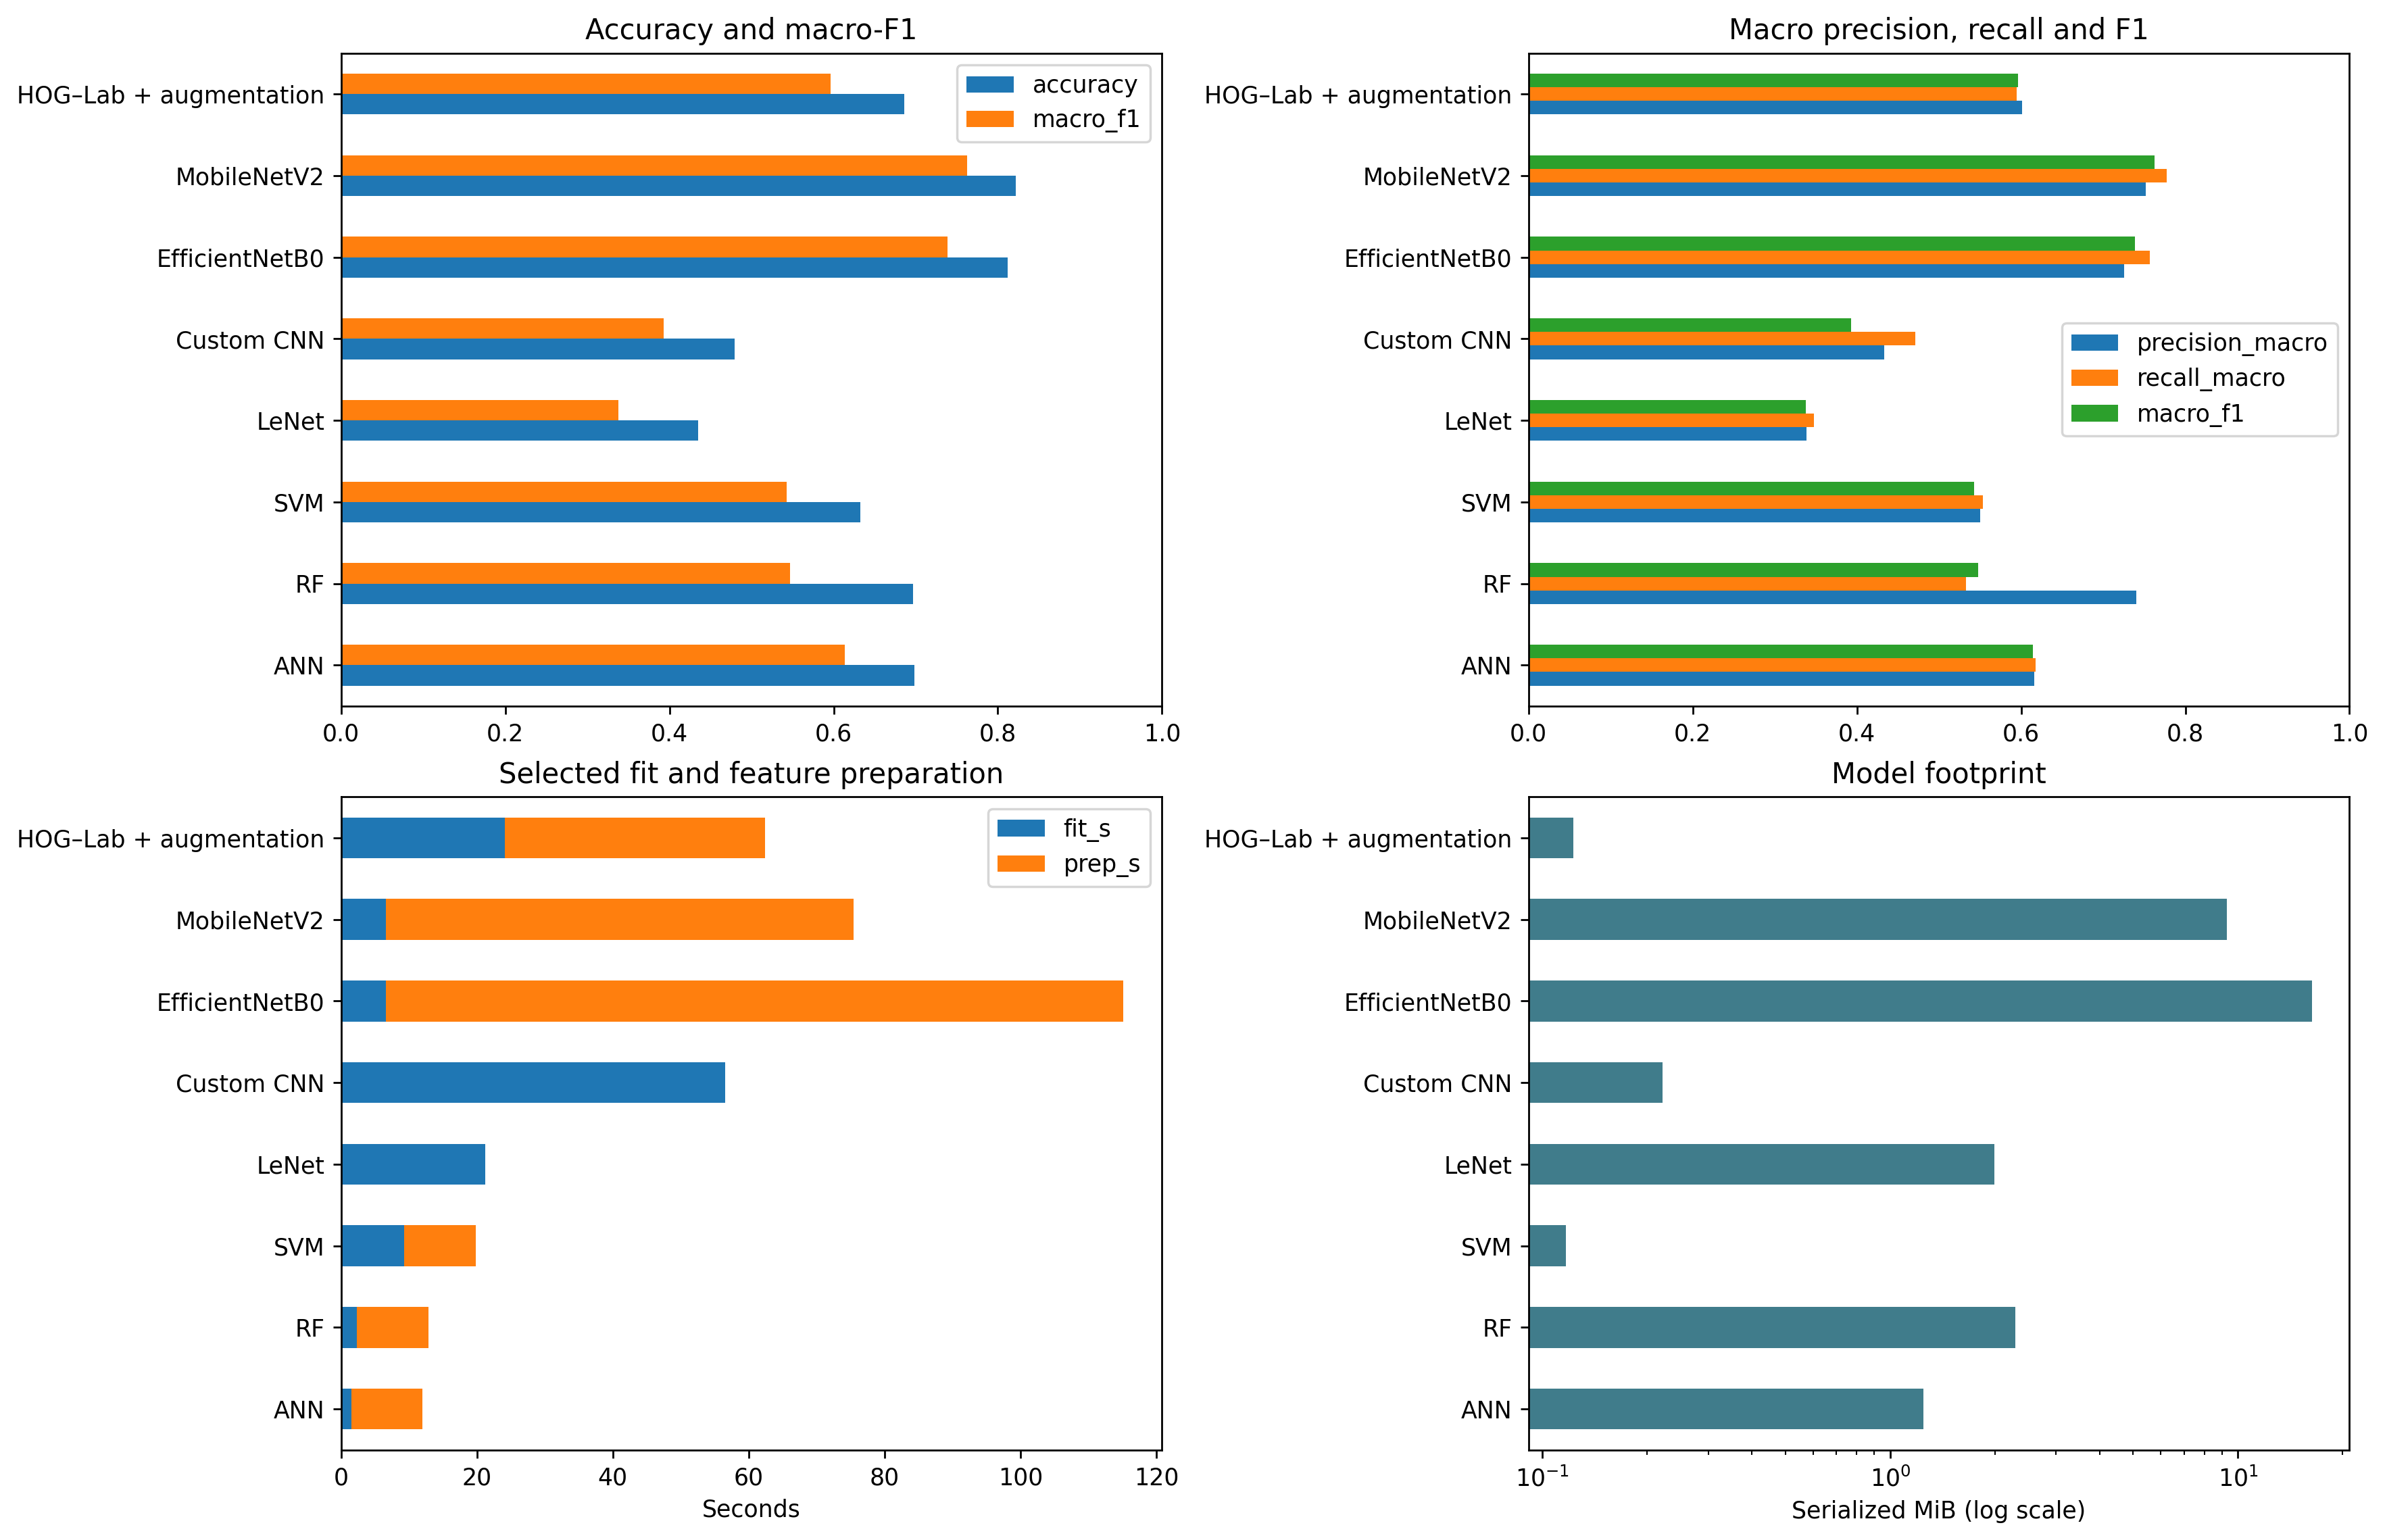

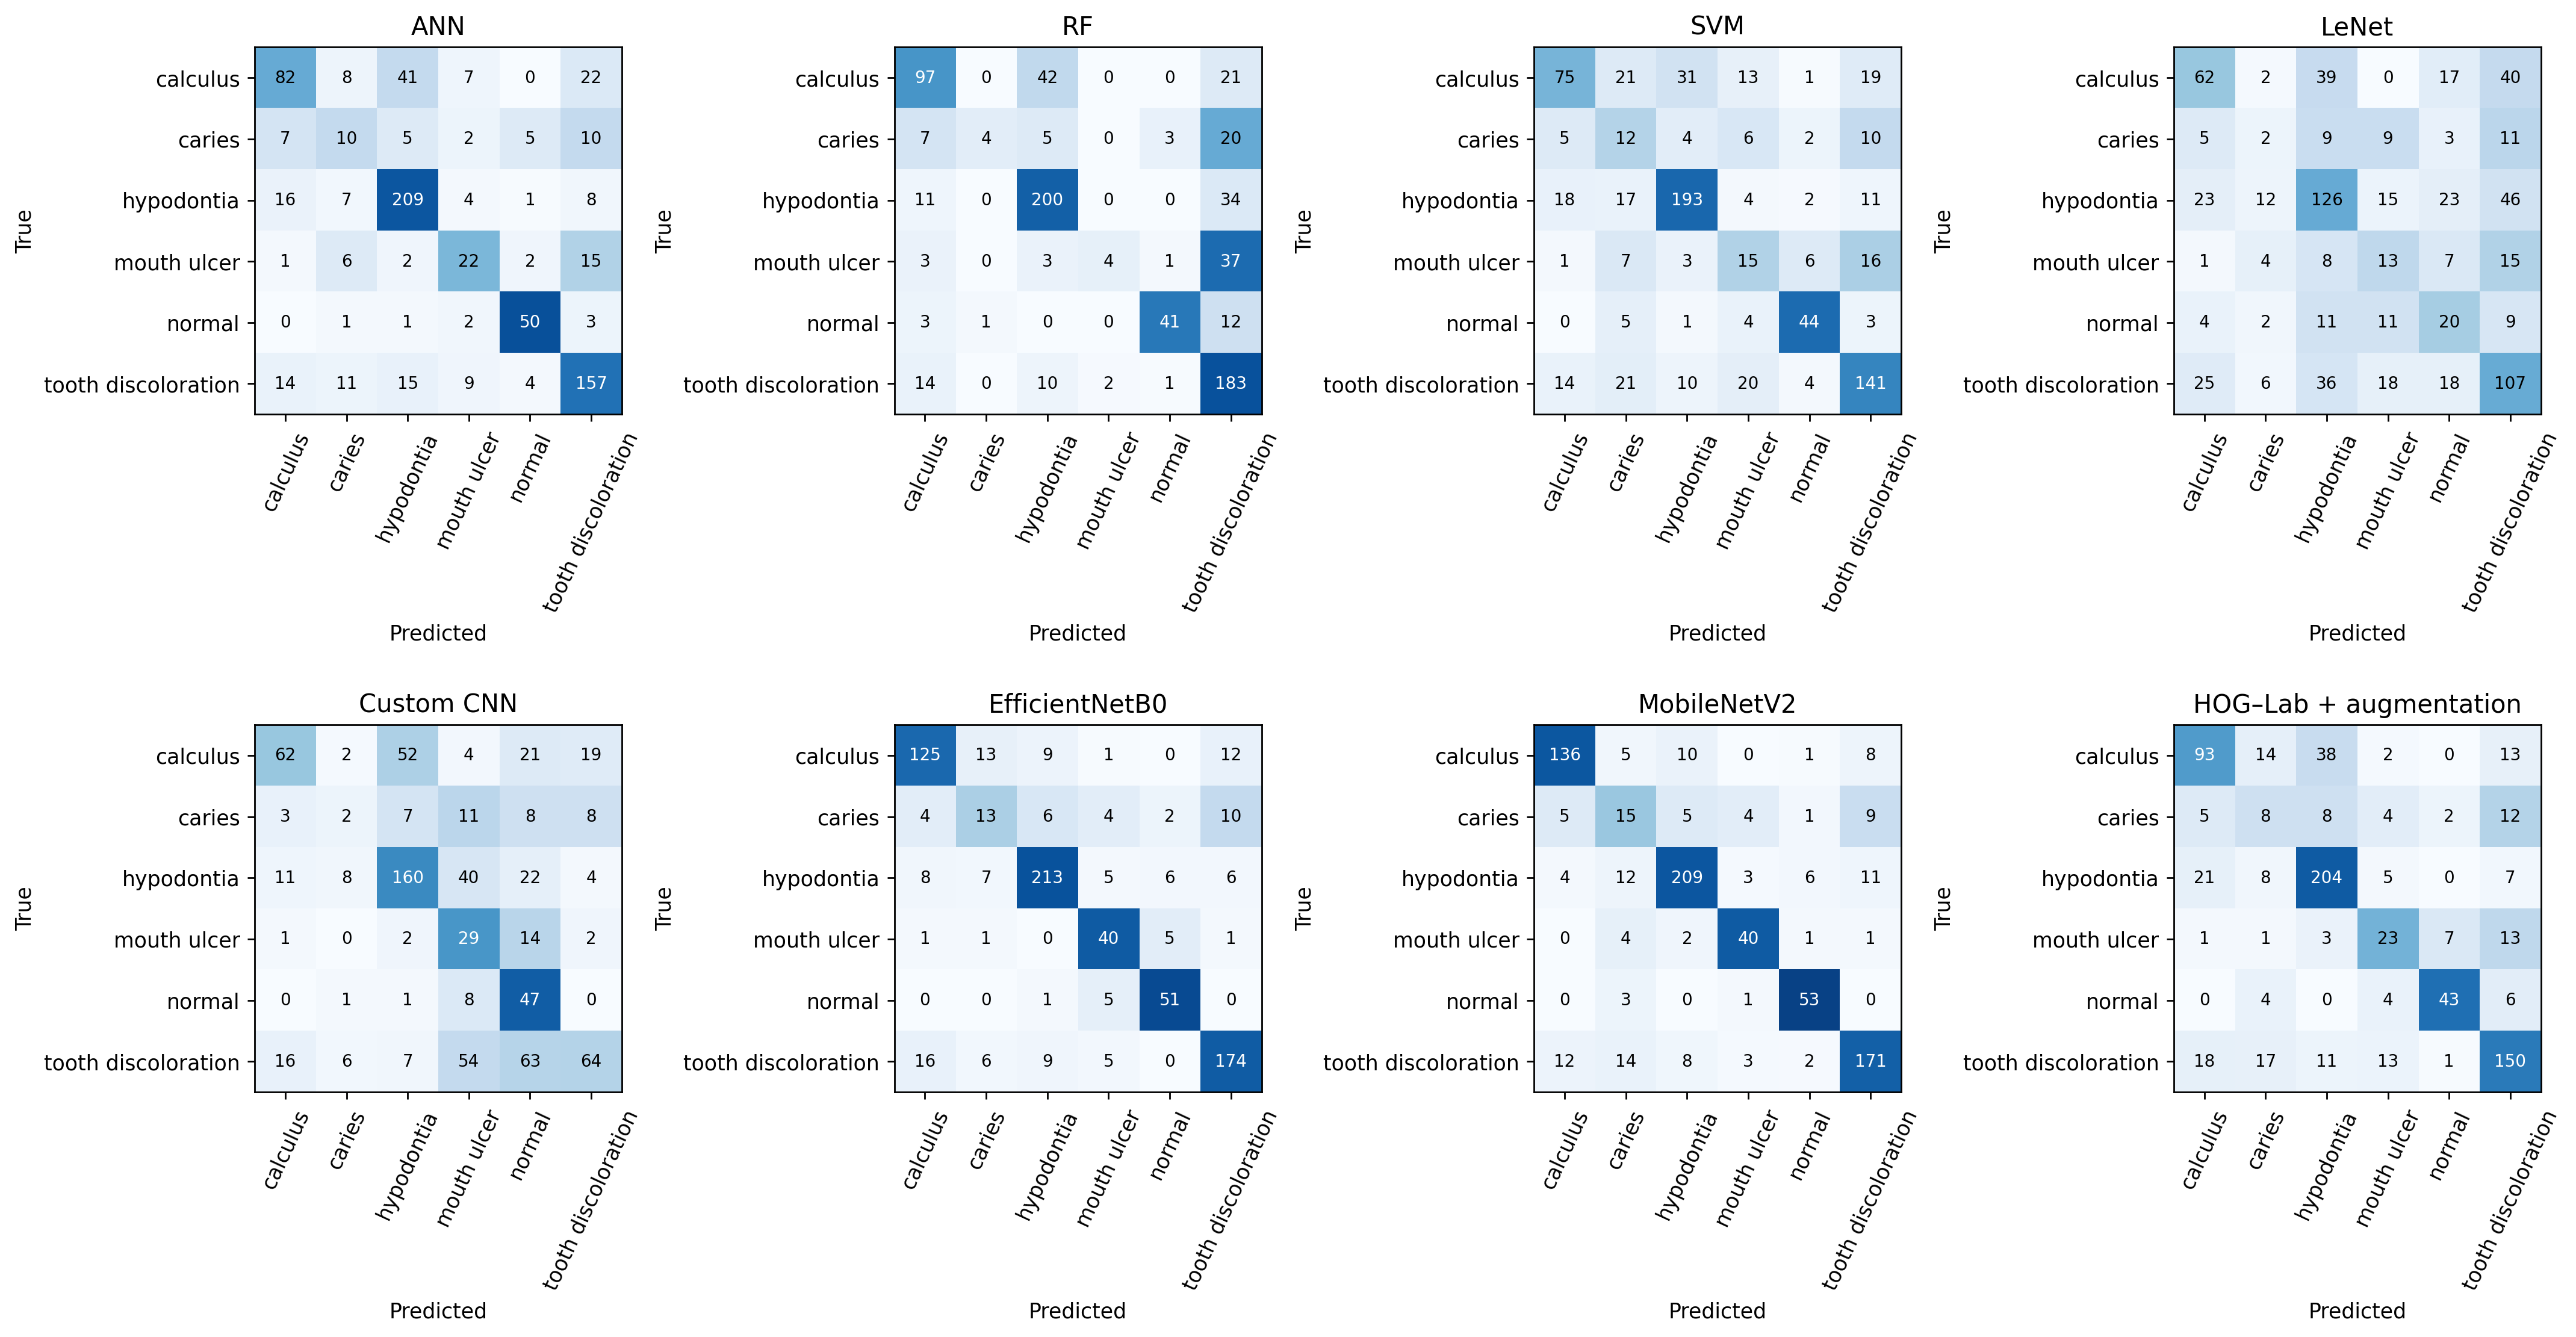

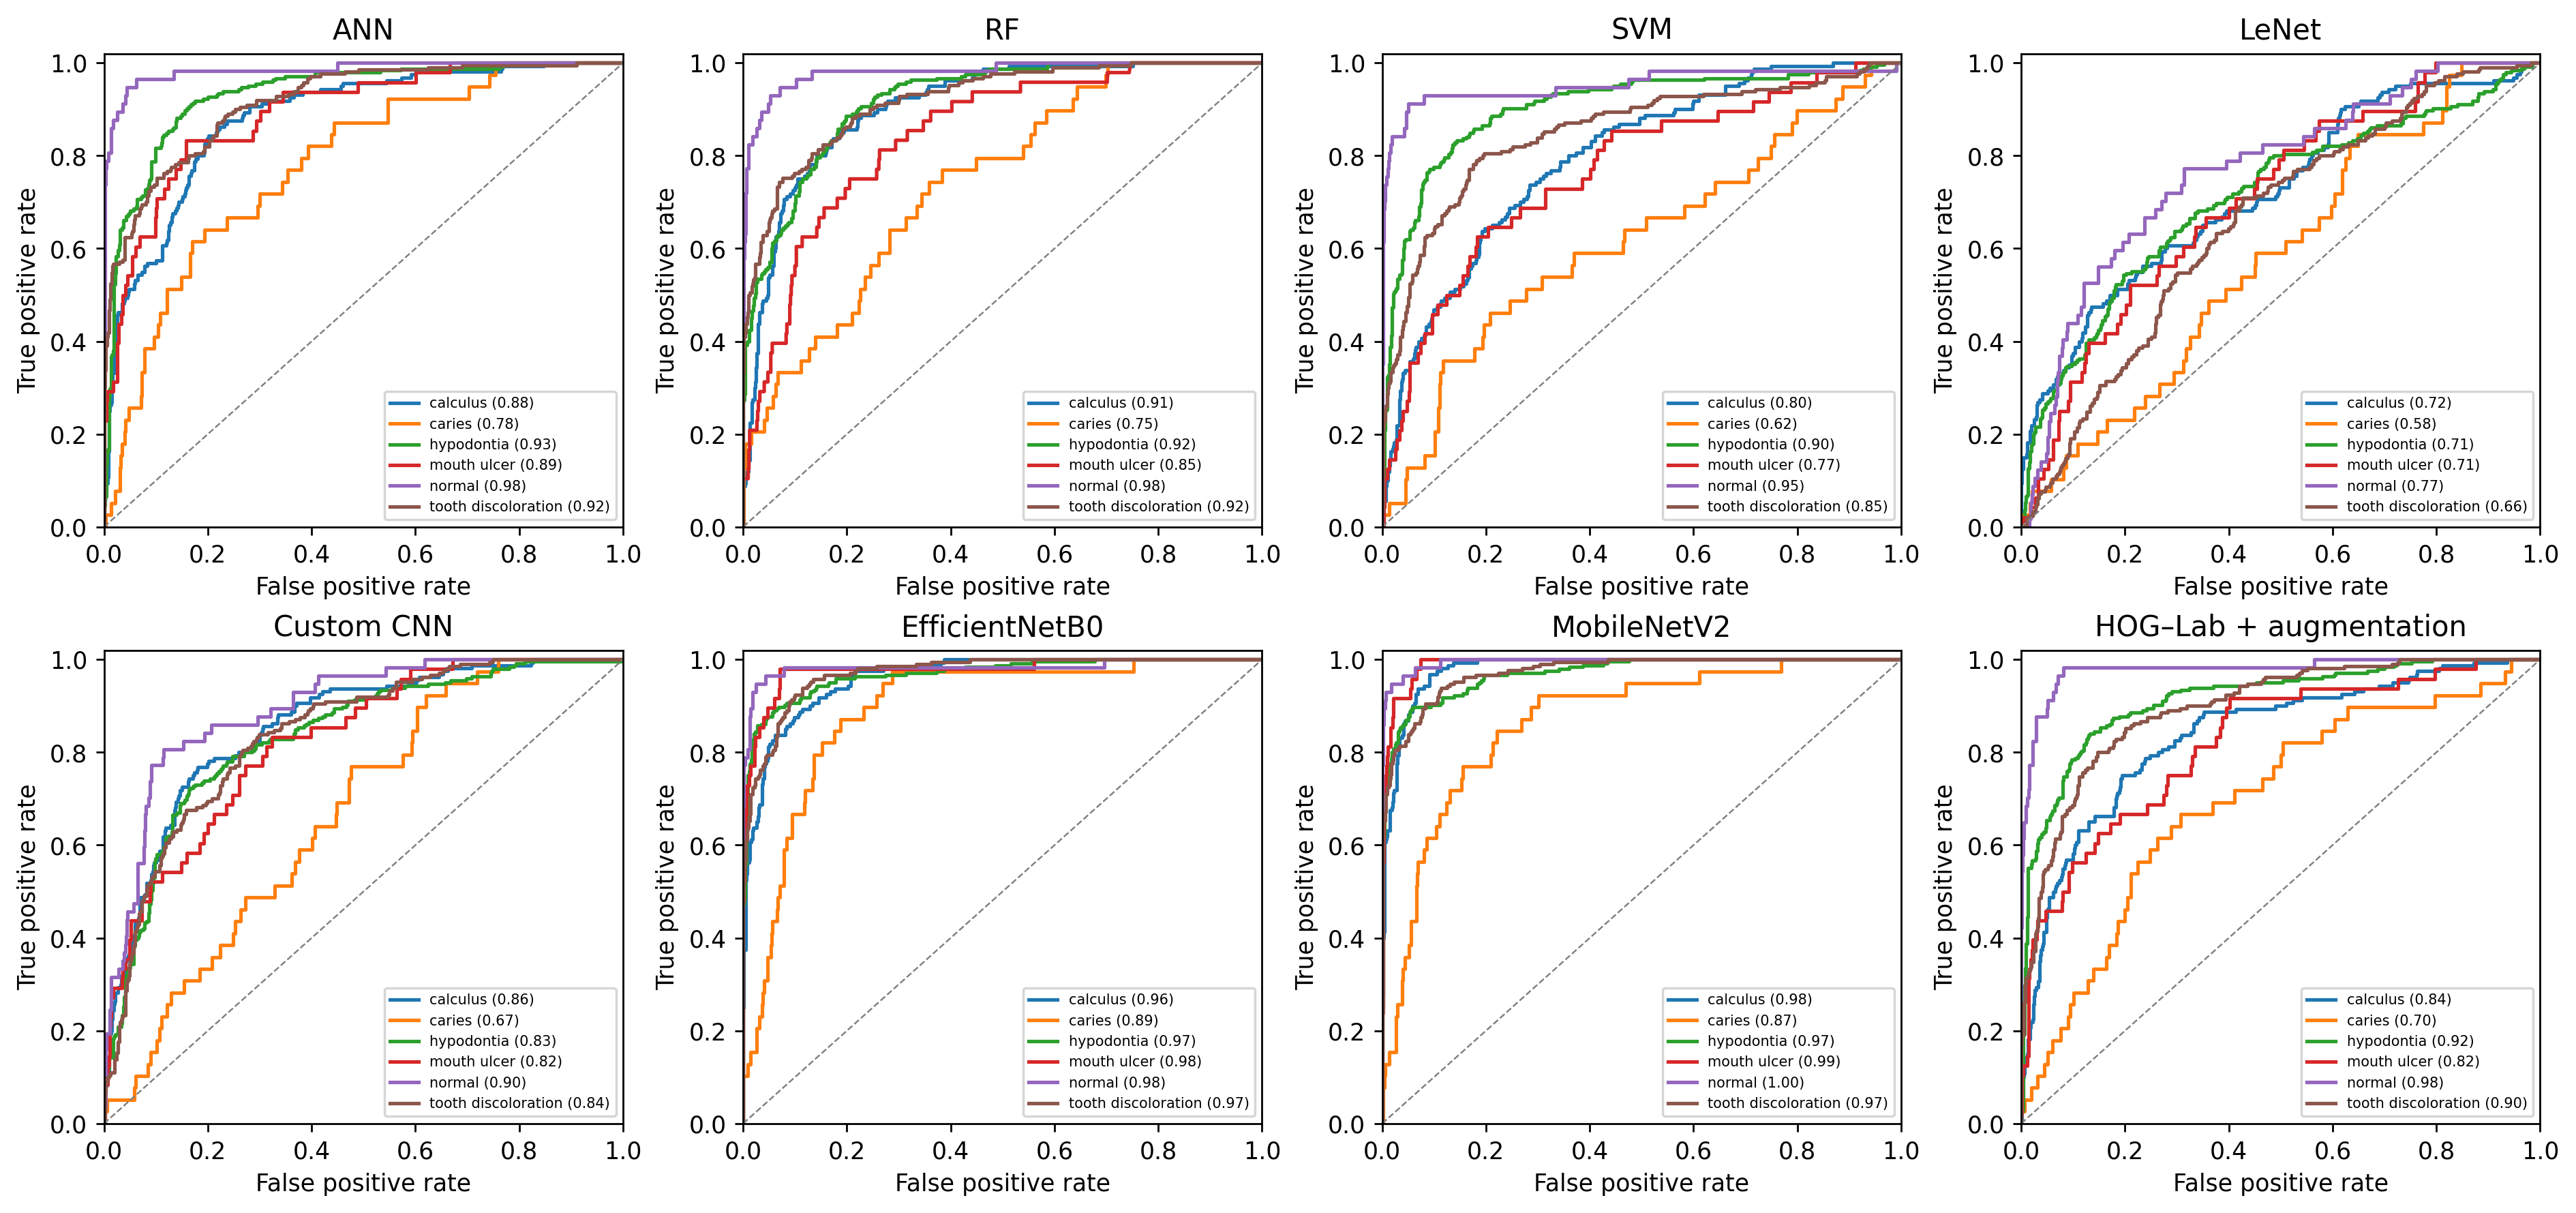

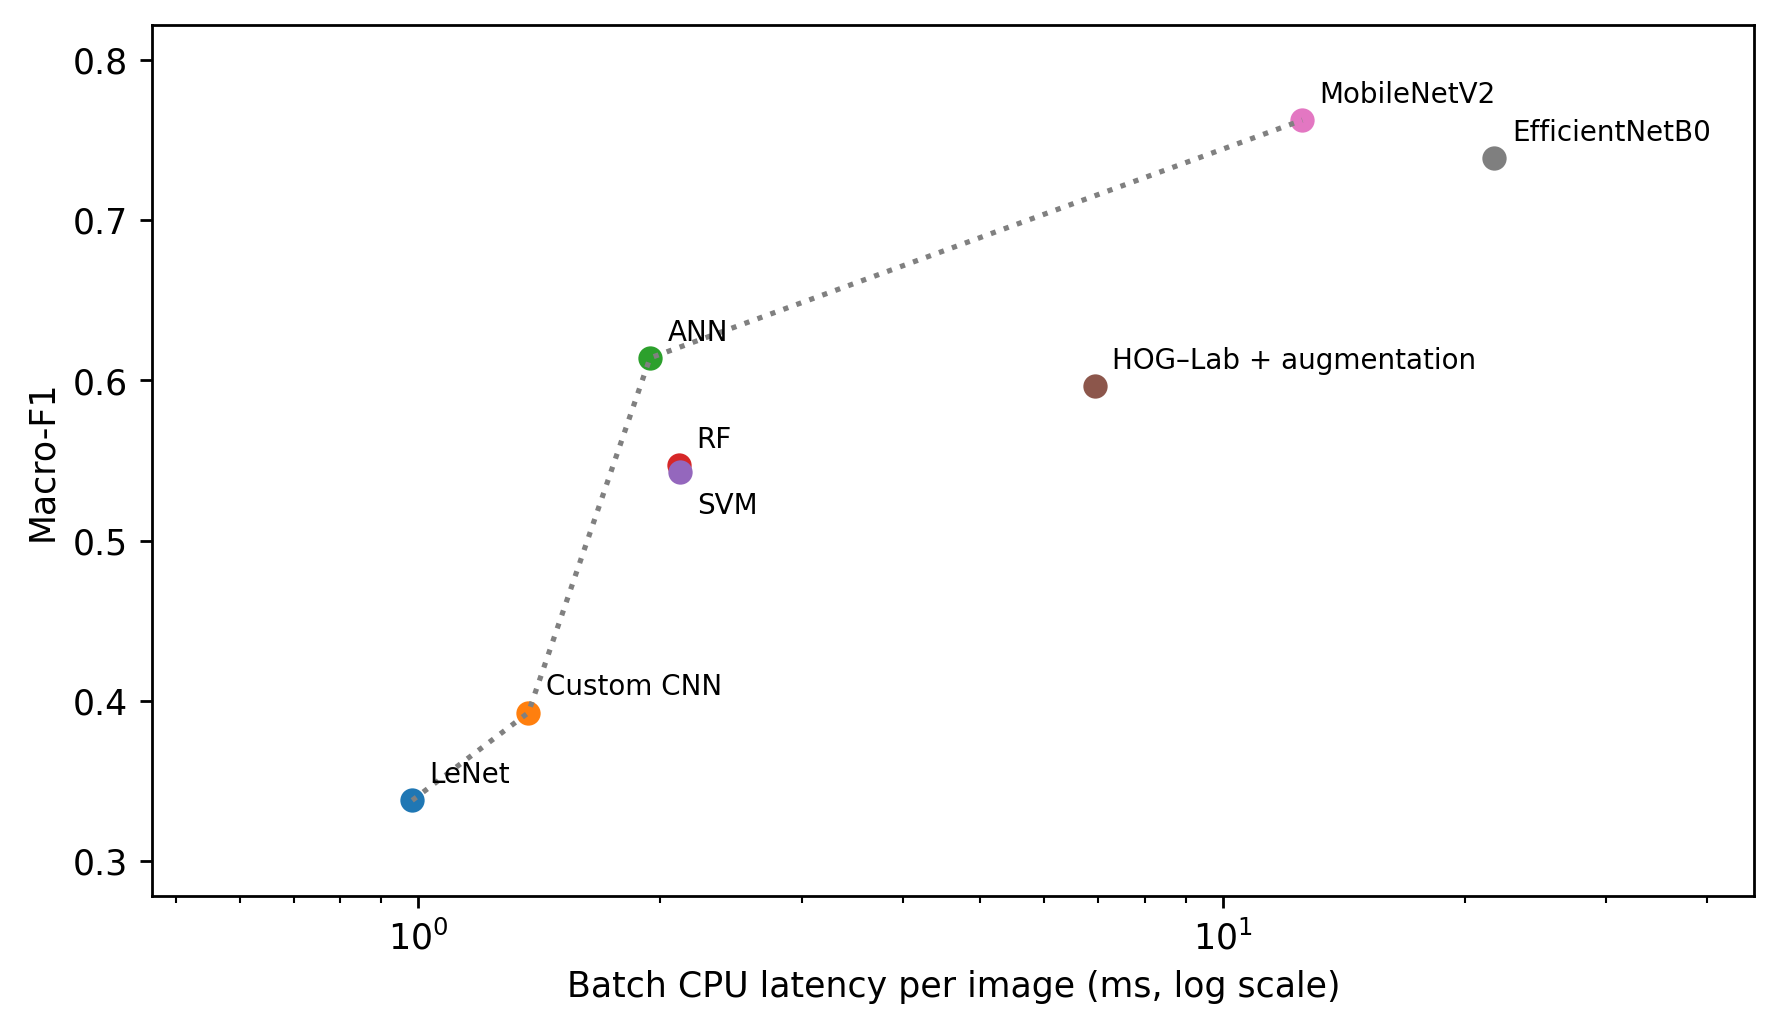

In [ ]:
fig, axes = plt.subplots(2,2,figsize=(14,9),constrained_layout=True)
main.rename(index=short)[['accuracy','macro_f1']].plot.barh(ax=axes[0,0],xlim=(0,1))
axes[0,0].set_title('Accuracy and macro-F1')
main.rename(index=short)[['precision_macro','recall_macro','macro_f1']].plot.barh(ax=axes[0,1],xlim=(0,1))
axes[0,1].set_title('Macro precision, recall and F1')
main.rename(index=short)[['fit_s','prep_s']].plot.barh(stacked=True,ax=axes[1,0])
axes[1,0].set(xlabel='Seconds',title='Selected fit and feature preparation')
main.rename(index=short)['size_mib'].plot.barh(ax=axes[1,1],logx=True,color='#407c8b')
axes[1,1].set(xlabel='Serialized MiB (log scale)',title='Model footprint')
for ax in axes.flat:
    ax.set_ylabel('')
save_plot(fig,'model_comparison')

fig,axes = plt.subplots(2,4,figsize=(17,9),constrained_layout=True)
confusions = []
for ax,name in zip(axes.flat,main_names):
    cm = confusion_matrix(y[test],predictions[name],labels=LABELS)
    confusions.extend((name,a,b,int(cm[i,j])) for i,a in enumerate(classes) for j,b in enumerate(classes))
    ax.imshow(cm/cm.sum(1,keepdims=True),vmin=0,vmax=1,cmap='Blues')
    for i,j in np.ndindex(cm.shape):
        ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=8,
                color='white' if cm[i,j]/cm[i].sum()>.55 else 'black')
    ax.set(xticks=LABELS,yticks=LABELS,xticklabels=classes,yticklabels=classes,title=short[name])
    ax.tick_params(axis='x',labelrotation=65)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
pd.DataFrame(confusions,columns=['model','true','predicted','n']).to_csv(OUT/'confusions.csv',index=False)
save_plot(fig,'confusion_matrices')

fig,axes = plt.subplots(2,4,figsize=(15,7),constrained_layout=True)
for ax,name in zip(axes.flat,main_names):
    for i,label in enumerate(classes):
        binary = y[test]==i
        score = score_matrices[name][:,i]
        fpr,tpr,_ = roc_curve(binary,score)
        ax.plot(fpr,tpr,label=f'{label} ({roc_auc_score(binary,score):.2f})')
    ax.plot([0,1],[0,1],color='grey',ls='--',lw=0.7)
    ax.set(xlabel='False positive rate',ylabel='True positive rate',title=short[name],
           xlim=(0,1),ylim=(0,1.02))
    ax.legend(loc='lower right',fontsize=6)
save_plot(fig,'one_vs_rest_roc')

tradeoff = main[['macro_f1','batch_ms_per_image']].sort_values('batch_ms_per_image')
front = tradeoff[tradeoff.macro_f1 > tradeoff.macro_f1.cummax().shift(fill_value=-1)]
fig,ax = plt.subplots(figsize=(7,4),layout='constrained')
ax.plot(front.batch_ms_per_image,front.macro_f1,':',color='gray')
for name,row in tradeoff.iterrows():
    ax.scatter(row.batch_ms_per_image,row.macro_f1)
    offset = (5,-12) if name == 'Linear SVM (HOG)' else (5,5)
    ax.annotate(short[name],(row.batch_ms_per_image,row.macro_f1),xytext=offset,
                textcoords='offset points',fontsize=8)
ax.set(xscale='log',xlabel='Batch CPU latency per image (ms, log scale)',ylabel='Macro-F1')
ax.margins(x=.24,y=.14)
save_plot(fig,'cpu_tradeoff')

ablations = results.loc[[proposed,clean_fusion,hog_only,lab_only,stretch],
                        ['validation_macro_f1','macro_f1','batch_ms_per_image']]
ablations.to_csv(OUT/'ablations.csv')
display(ablations.round(4))

## 10 · Classwise errors and robustness
Rank confusion directions and inspect deterministic examples from the largest error pair for the validation-selected comparator and fusion. Treat content and label ambiguity as qualitative findings. Stress all eight models and the clean-fusion control using the same test images and fixed blur, brightness, and JPEG settings at 96×96. These are synthetic camera-degradation probes and reuse the augmentation families; they evaluate in-family robustness only.

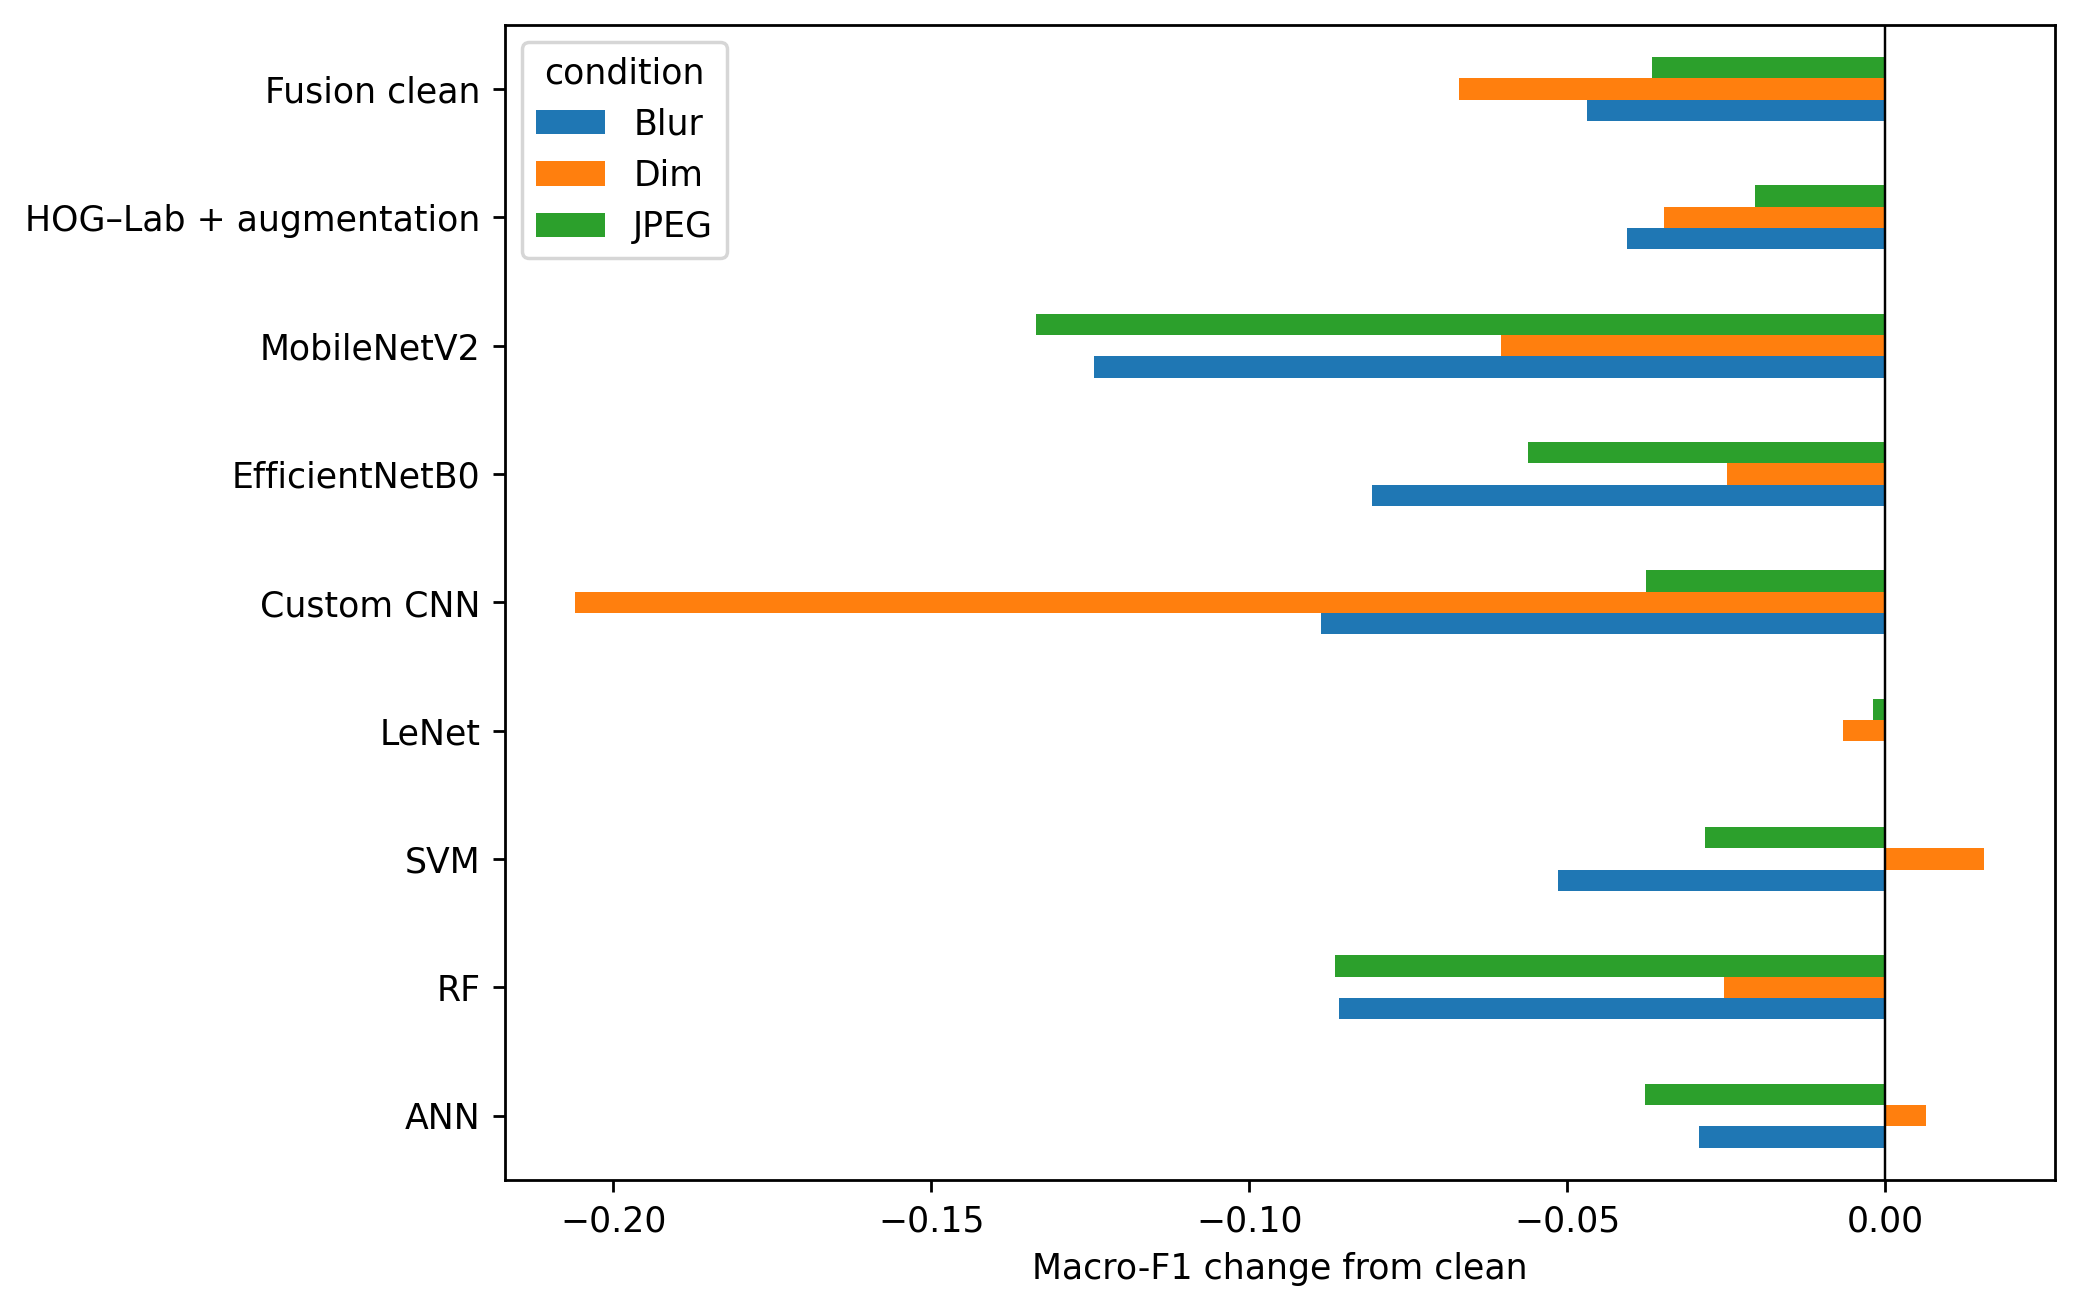

In [ ]:
pair_table = pd.DataFrame(confusions,columns=['model','true','predicted','n'])
errors = pair_table.query('true != predicted and n > 0').sort_values('n',ascending=False)
errors.to_csv(OUT/'errors.csv',index=False)
for name in (baseline,proposed):
    subset = errors[errors.model==name]
    display(subset.head(5))
    if len(subset):
        worst = subset.iloc[0]
        ii = np.flatnonzero((y[test]==classes.index(worst['true'])) &
                            (predictions[name]==classes.index(worst['predicted'])))[:4]
        fig,axes = plt.subplots(1,len(ii),figsize=(2.2*len(ii),2.6),squeeze=False)
        for ax,j in zip(axes.flat,ii):
            ax.imshow(common_test[j])
            ax.set_title(f'Test row {int(j)}')
            ax.axis('off')
        fig.suptitle(f'{short[name]} | {worst["true"]} → {worst["predicted"]}',fontsize=10)
        plt.show()
        plt.close(fig)

robust_rows = []
for condition in conditions:
    altered = np.stack([perturb(im,condition) for im in common_test])
    paired = extract(altered,'fusion')
    feature_map = {'hog':paired[:,:HOG_DIM],'lab':paired[:,HOG_DIM:],'fusion':paired}
    for name in [*main_names,clean_fusion]:
        record = registry[name]
        scores = (forward(record['model'],altered) if record['feature']=='rgb'
                  else scores_for(record['model'],feature_map[record['feature']]))
        pred = prediction_labels(record,scores)
        f1 = macro(y[test],pred)
        robust_rows.append(dict(model=name,condition=condition,macro_f1=f1,
                                accuracy=accuracy_score(y[test],pred),
                                delta_vs_clean=f1-results.at[name,'macro_f1']))
robust = pd.DataFrame(robust_rows)
robust.to_csv(OUT/'robustness.csv',index=False)
display(robust.pivot(index='model',columns='condition',values='macro_f1').round(4))
ax = robust.pivot(index='model',columns='condition',values='delta_vs_clean').loc[
    [*main_names,clean_fusion]].rename(index=short).plot.barh(figsize=(8,6),xlabel='Macro-F1 change from clean')
ax.axvline(0,color='black',lw=0.7)
ax.set_ylabel('')
save_plot(ax.figure,'robustness_delta')

## 11 · Paired statistical analysis
Resample approximate duplicate groups as blocks. The 95% percentile intervals condition on the fitted models and this test set. Compare the proposed method to the validation-selected mandatory baseline with a two-sided paired group-wise prediction-swap test (exchangeability assumed under the null). Group bootstrap intervals for ablations are exploratory. Residual dependency across groups or shared upstream sources can still invalidate independence. This design does not estimate training-seed or external-site variation.

In [ ]:
unique_groups, gi = np.unique(groups[test],return_inverse=True)
G = len(unique_groups)
group_counts = {}
for name,pred in predictions.items():
    mats = np.zeros((G,K,K),dtype=np.int64)
    np.add.at(mats,(gi,y[test],pred),1)
    group_counts[name] = mats

def f1_from_cm(cm):
    diag = np.diagonal(cm,axis1=-2,axis2=-1)
    denominator = cm.sum(-1)+cm.sum(-2)
    return np.divide(2*diag,denominator,out=np.zeros_like(diag,dtype=float),
                     where=denominator>0).mean(axis=-1)

rng = np.random.default_rng(SEED+100)
draws = rng.integers(0,G,(2000,G))
bootstrap = {}
for name,mats in group_counts.items():
    bootstrap[name] = np.concatenate([f1_from_cm(mats[chunk].sum(axis=1))
                                     for chunk in np.array_split(draws,40)])
intervals = []
for name,values in bootstrap.items():
    lo,hi = np.quantile(values,[.025,.975])
    intervals.append((name,results.at[name,'macro_f1'],lo,hi))
pd.DataFrame(intervals,columns=['model','macro_f1','lo_95','hi_95']).to_csv(OUT/'bootstrap_ci.csv',index=False)

def compare_pair(a,b,primary=False):
    delta = results.at[a,'macro_f1']-results.at[b,'macro_f1']
    lo,hi = np.quantile(bootstrap[a]-bootstrap[b],[.025,.975])
    row = dict(a=a,b=b,delta=delta,lo_95=lo,hi_95=hi,paired_p=np.nan)
    if primary:
        first,second = group_counts[a],group_counts[b]
        extremes = 0
        for _ in range(2000):
            swap = rng.integers(0,2,(G,1,1)).astype(bool)
            d = f1_from_cm(np.where(swap,second,first).sum(0))-f1_from_cm(np.where(swap,first,second).sum(0))
            extremes += abs(d) >= abs(delta)-1e-12
        row['paired_p'] = (extremes+1)/2001
    return row

paired_results = pd.DataFrame([compare_pair(proposed,baseline,True),
                               *[compare_pair(proposed,name) for name in (clean_fusion,hog_only,lab_only,stretch)]])
paired_results.to_csv(OUT/'paired_statistics.csv',index=False)
display(paired_results.round(4))
print('Test groups:',G)

## 12 · Discussion, limitations, conclusion, and manuscript plan
Use the validation-selected comparator for the primary inferential claim. Use test rankings descriptively. Report the sign and interval of the paired difference even if fusion underperforms. Compare clean and augmented fusion using both clean metrics and mean perturbation change. Interpret classwise errors alongside class counts and inspect recurring artefacts before making visual explanations. A fast baseline can be practically preferable even if another model is marginally better.

A single archive cannot establish patient-level generalization, clinical triage utility, or diagnostic safety. Exact conflicts expose label uncertainty. Perceptual hashes provide partial leakage control, and class folders may encode upstream source cues, borders, acquisition methods or image editing. Color features can learn those cues. Image-level categories may conflate visible findings and clinical diagnoses. Synthetic degradations do not model clinic, camera, or population shifts. CPU latency is machine-specific. Future validation should use clinician-reviewed labels, patient- and source-level grouping, independently collected images, repeated training seeds and device benchmarking.

| Manuscript section | Include |
|---|---|
| Abstract | Dataset, audited split, method, observed primary difference with interval, and CPU cost |
| Introduction | Motivation, research questions, and why cheap features warrant testing |
| Related Work | Oral photograph classifiers, prior hybrid methods, and leakage risks |
| Methodology | Exact and perceptual audit, split, HOG–Lab block weighting, training-only perturbation |
| Experimental Setup | Release, manifest, hardware and versions, tuning budget, metrics, test protocol |
| Results and Discussion | Main metrics, uncertainty, confusion pairs, ablations, stress tests and efficiency frontier |
| Limitations | Label and provenance concerns, synthetic degradation, external validity and repeated-seed limits |
| Conclusion | State the empirical finding within the archive and specify independent validation needed |

Publish the code, manifest, and aggregate results where redistribution is permitted. Verify the upstream image rights before reproducing example photos. Frame this as a reproducibility and efficiency benchmark with a controlled ablation study.

In [ ]:
primary = paired_results.iloc[0]
best = main.macro_f1.idxmax()
fastest = main.batch_ms_per_image.idxmin()
print(f'Highest clean test macro-F1: {best} ({main.at[best,"macro_f1"]:.4f})')
print(f'Fastest batched inference: {fastest} ({main.at[fastest,"batch_ms_per_image"]:.3f} ms/image)')
print('Pareto frontier:', ', '.join(front.index))
print(f'Primary difference: {primary.delta:+.4f}, 95% CI [{primary.lo_95:+.4f}, '
      f'{primary.hi_95:+.4f}], p={primary.paired_p:.4f}')
assert len(main) == 8 and len(test_predictions) == len(test)
print(f'Results and trained models saved under {OUT}')

## Reference results from the full CPU execution

The reference run trained and evaluated all seven mandatory models, the proposed fusion and four controls on the actual Kaggle archive in a local CPU runtime. Kaggle hosted execution was not performed. TensorFlow 2.21.0 and scikit-learn 1.8.0 ran with a four-thread budget. Both Keras backbones loaded ImageNet weights. The MLP reached its 35-iteration cap in both trials with a convergence warning.

The reference run finished in approximately 17 minutes from setup to final results on the available CPU. Dataset download and extraction were performed beforehand. The training ledger records a discarded high-C HOG SVM trial that took about 152 seconds.

The validation-selected comparator was **MobileNetV2**. Augmented fusion achieved 0.5963 clean macro-F1. Its score was 0.1662 lower than the comparator. The paired difference was -0.1662, 95% group-bootstrap CI [-0.2218, -0.1128], paired two-sided p=0.0005. These estimates condition on this split and fitted models.

The highest test macro-F1 was **MobileNetV2** (0.7625). The fastest batch result was **LeNet-style CNN** (0.983 ms/image). The observed batch-latency/macro-F1 frontier contained LeNet-style CNN, Custom CNN, ANN (HOG), MobileNetV2. Latency includes feature extraction or the backbone on resized images.

Under matched SVM settings and augmented views, HOG–Lab fusion improved clean macro-F1 by +0.0550 compared with HOG alone (exploratory 95% CI [+0.0210, +0.0871]). Camera augmentation changed clean macro-F1 by +0.0020 versus clean-only fusion, and changed mean corrupted-image macro-F1 across the three conditions by +0.0203. The largest confusion for each highlighted model was MobileNetV2: tooth discoloration → caries (14 images) and HOG–Lab fusion + camera augmentation: calculus → hypodontia (38 images).

### Clean test comparison

| Model | Accuracy | Macro precision | Macro recall | Macro-F1 | Weighted F1 | ROC-AUC | Average precision | CPU ms/image |
|---|---|---|---|---|---|---|---|---|
| ANN (HOG) | 0.6983 | 0.6161 | 0.6175 | 0.6140 | 0.6936 | 0.8983 | 0.6645 | 1.9412 |
| Random Forest (HOG) | 0.6970 | 0.7403 | 0.5332 | 0.5473 | 0.6687 | 0.8867 | 0.6496 | 2.1070 |
| Linear SVM (HOG) | 0.6324 | 0.5498 | 0.5533 | 0.5430 | 0.6463 | 0.8153 | 0.5519 | 2.1144 |
| LeNet-style CNN | 0.4348 | 0.3386 | 0.3474 | 0.3378 | 0.4384 | 0.6911 | 0.3097 | 0.9828 |
| Custom CNN | 0.4796 | 0.4329 | 0.4709 | 0.3925 | 0.4895 | 0.8196 | 0.4796 | 1.3706 |
| EfficientNetB0 | 0.8116 | 0.7254 | 0.7568 | 0.7389 | 0.8127 | 0.9591 | 0.8185 | 21.7727 |
| MobileNetV2 | 0.8221 | 0.7516 | 0.7775 | 0.7625 | 0.8270 | 0.9635 | 0.8294 | 12.5648 |
| HOG–Lab fusion + camera augmentation | 0.6864 | 0.6015 | 0.5945 | 0.5963 | 0.6894 | 0.8584 | 0.6051 | 6.9325 |

### Runtime and complexity

| Model | Fit s | Prep s | Single ms | Trainable | Total | Tree nodes | MiB |
|---|---|---|---|---|---|---|---|
| ANN (HOG) | 1.477 | 10.539 | 2.515 | 85014.000 | 85014.000 | — | 1.245 |
| Random Forest (HOG) | 2.367 | 10.539 | 49.030 | — | — | 64372.000 | 2.287 |
| Linear SVM (HOG) | 9.276 | 10.539 | 2.683 | 10590.000 | 10590.000 | — | 0.117 |
| LeNet-style CNN | 21.214 | 0.000 | 17.525 | 168886.000 | 168889.000 | — | 1.993 |
| Custom CNN | 56.554 | 0.000 | 17.119 | 11702.000 | 12134.000 | — | 0.221 |
| EfficientNetB0 | 6.584 | 108.500 | 408.756 | 7686.000 | 4057257.000 | — | 16.352 |
| MobileNetV2 | 6.566 | 68.854 | 205.482 | 7686.000 | 2265670.000 | — | 9.273 |
| HOG–Lab fusion + camera augmentation | 24.141 | 38.301 | 6.964 | 11166.000 | 11166.000 | — | 0.123 |

### Ablations

| Model | macro_f1 | validation_macro_f1 |
|---|---|---|
| HOG–Lab fusion + camera augmentation | 0.5963 | 0.5786 |
| Fusion / no camera augmentation | 0.5943 | 0.5841 |
| HOG only / camera augmentation | 0.5413 | 0.5500 |
| Lab only / camera augmentation | 0.2862 | 0.2964 |
| Fusion / stretch resize | 0.5225 | 0.5321 |

### Camera degradation macro-F1

| Model | Blur | Dim | JPEG |
|---|---|---|---|
| ANN (HOG) | 0.5848 | 0.6204 | 0.5762 |
| Random Forest (HOG) | 0.4615 | 0.5220 | 0.4608 |
| Linear SVM (HOG) | 0.4916 | 0.5586 | 0.5146 |
| LeNet-style CNN | 0.3380 | 0.3312 | 0.3359 |
| Custom CNN | 0.3038 | 0.1866 | 0.3550 |
| EfficientNetB0 | 0.6582 | 0.7140 | 0.6827 |
| MobileNetV2 | 0.6381 | 0.7021 | 0.6290 |
| HOG–Lab fusion + camera augmentation | 0.5558 | 0.5616 | 0.5758 |
| Fusion / no camera augmentation | 0.5474 | 0.5274 | 0.5576 |

### Clean macro-F1 confidence intervals

| Model | macro_f1 | lo_95 | hi_95 |
|---|---|---|---|
| ANN (HOG) | 0.6140 | 0.5641 | 0.6599 |
| Random Forest (HOG) | 0.5473 | 0.4963 | 0.5938 |
| Linear SVM (HOG) | 0.5430 | 0.4975 | 0.5854 |
| LeNet-style CNN | 0.3378 | 0.2917 | 0.3822 |
| Custom CNN | 0.3925 | 0.3537 | 0.4326 |
| EfficientNetB0 | 0.7389 | 0.6912 | 0.7829 |
| MobileNetV2 | 0.7625 | 0.7222 | 0.8010 |
| HOG–Lab fusion + camera augmentation | 0.5963 | 0.5487 | 0.6386 |
